# Introduction to Machine Learning -- MC886
# Assignment 1 - Linear Models

**Professor:** Marcelo da Silva Reis\
**PED:** Heigon Alafaire Soldera Pires


In [1]:
# Please, enter your name and RA number in the lines below:
print("Lucas Gomes Bussinger da Silva", "|", "247314")
print("Caíque Andrade", "|", "204677")
print("Jorge Felipe Lopes Pereira", "|", "251771") # You may remove this line if you are only 2 students in the group

Lucas Gomes Bussinger da Silva | 247314
Caíque Andrade | 204677
Jorge Felipe Lopes Pereira | 251771



## Objective

The objective with this assignment is to explore **Linear Regression** and other
**Generalized Linear Models** to come up with the best model for the problem.
Remember, the goal is not just getting the code running, but gathering a deeper
understanding on **how** these algorithms work and **why** choosing them in the
first place.

Every model choice has implicit assumptions about the data, the goal here is to
understand the underlying assumptions and critically address the limitations
introduced by them.

### **Guidelines**
> Please, read these guidelines carefully

1. The questions can be answered in English or in Portuguese.

2. We incentivize visualizing the (training) data to gather insight about the
problem and the solutions. If you are not sure about an assumption, plot it!

3. The existing code in this notebook is just a mere reference. You are free to
change the code as much as you need. You will not be penalized for changing a 
function signature or implementing more functions/classes.
**Just make the code readable!**

4. The use of generative AI (ChatGPT, DeepSeek, Llama, GitHub Copilot, etc.) is
permitted to assist in completing assignments. In such cases the submitted work
**must** include a statement specifying the models used and, if
applicable, a transcription of the prompts employed to generate the code
incorporated into the solution.
However, using AI to analyse and discuss the results is discouraged.

5. The final performance of your model is not the main goal, explaining why the
model has such a performance (it being good or bad) is more important than the
metric value per se.

6. Metrics are not detached values, revisit the math behind them to understand
what they are trying to say about your model.

7. Do not hesitate in reaching the PED via Discord.

---
### **Dataset**
The dataset we will be using is the [Metro Interstate Traffic Volume](https://archive.ics.uci.edu/dataset/492/metro+interstate+traffic+volume)
dataset, an hourly count of vehicles on the westbound Interstate 94, measured by
the MnDOT sensor ATR 301, roughly midway between Minneapolis and St. Paul (MN),
between 2015 and 2018.
Each observation joins the traffic counter with the weather reported for that
same hour and with the holiday calendar.

The data has 26677 samples with the following columns

feature | description | data type
--- | --- | ---
**instant** | Integer identifier | Integer
**date** | Date of the observation | Date
**season** | The season (1 Winter, 2 Spring, 3 Summer, 4 Fall) | Categorical
**yr** | Year (0 for 2015, 1 for 2016, 2 for 2017 and 3 for 2018) | Categorical
**mnth** | The month number | Categorical
**hr** | The hour number | Categorical
**holiday** | Whether the day is a national holiday (or the Minnesota State Fair) | Boolean
**weekday** | The day of the week (0 is Sunday) | Categorical
**workingday** | If the day is neither a holiday nor a weekend | Boolean
**weather** | Current weather (Clear, Clouds, Rain, Snow, Mist, ...) | Categorical
**weather_desc** | A longer description of the current weather | Categorical
**temp** | Temperature in °C | Continuous
**rain_1h** | Rain that fell during the hour, in mm | Continuous
**snow_1h** | Snow that fell during the hour, in mm | Continuous
**clouds_all** | Cloud cover in % | Continuous
**traffic_volume** | Count of vehicles reported in the hour | Integer

The goal will be inferring the traffic volume of an hour only using datetime and
weather information provided in the dataset.

> **Note:** this data comes from real sensors and was only lightly cleaned for
> you. Some hours are absent from the record and a few readings are physically
> implausible. Deciding what (if anything) to do about them is part of the
> assignment.

*Source: Hogue, J. (2019). Metro Interstate Traffic Volume. UCI Machine Learning
Repository (CC BY 4.0).*


In [2]:
# Importing the necessary libraries
# Remember to re-visit the Hands-on 1 notebooks to setup your environment
from numpy.typing import NDArray
import numpy as np

import pandas as pd
import random

# This notebook already has some plot examples in matplotlib, but feel free to
# use other libraries (e.g., seaborn, plotly) if you prefer
import matplotlib.pyplot as plt

# To ensure reproducibility, set the random seed to your
# favorite number (e.g., your RA number)
np.random.seed(42)
random.seed(42)

# Do not tune this number to get better results, it is just to ensure that
# we all have the same random numbers and, therefore, the same results
# Re-run the notebook from the beginning (Run All) before submitting to classroom

In [3]:
# The dataset is available in the classroom assignment, ensure you have downloaded
# it and placed it in the same folder as this notebook

# Load the dataset
df = pd.read_csv("traffic_volume.csv")

df["date"] = pd.to_datetime(df["date"])
df


,instant,date,season,yr,mnth,hr,holiday,weekday,workingday,weather,weather_desc,temp,rain_1h,snow_1h,clouds_all,traffic_volume
0,1,2015-06-11,3,0,6,20,0,4,1,Rain,light rain,14.44,0.0,0.0,92,2886
1,2,2015-06-12,3,0,6,18,0,5,1,Clear,Sky is Clear,24.39,0.0,0.0,0,4380
2,3,2015-06-12,3,0,6,20,0,5,1,Clear,sky is clear,18.91,0.0,0.0,8,3095
3,4,2015-06-12,3,0,6,21,0,5,1,Clear,sky is clear,18.91,0.0,0.0,8,3299
4,5,2015-06-13,3,0,6,21,0,6,0,Clouds,broken clouds,21.69,0.0,0.0,76,3040
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26672,26673,2018-09-30,4,3,9,19,0,0,0,Clouds,broken clouds,10.30,0.0,0.0,75,3543
26673,26674,2018-09-30,4,3,9,20,0,0,0,Clouds,overcast clouds,9.61,0.0,0.0,90,2781
26674,26675,2018-09-30,4,3,9,21,0,0,0,Thunderstorm,proximity thunderstorm,9.58,0.0,0.0,90,2159
26675,26676,2018-09-30,4,3,9,22,0,0,0,Clouds,overcast clouds,8.94,0.0,0.0,90,1450


Note that the data is time-ordered, and consecutive samples are (usually) 1 hour
apart from each other. Beware that the record is not perfectly regular: some
hours were never reported by the sensor.
The idea is to predict future traffic volume from past data, thus our evaluation
protocol must respect the temporal order.
Therefore, we select the first 80% samples to compose the training data, and the
remaining 20% will be used for testing purposes.

**Important:** Never take decisions over the test dataset, it must be only used after
all models are trained (in the Test Evaluation section).
Any decision made using test information is called [data leakage](https://en.wikipedia.org/wiki/Leakage_(machine_learning)) and will be penalized.


In [4]:
train_size = int(0.8 * len(df))

train_df = df[:train_size]
test_df = df[train_size:]

# Securing that df will not be used anymore, to avoid mistakes
del df

print("Train set size:", len(train_df))
print("Test set size:", len(test_df))

Train set size: 21341
Test set size: 5336


---

## **Data Analysis and Preprocessing**

This part of the assignment aims to analyze the dataset and preprocess
the data for the models.


(0.5 points) 
First, consider possible problems in your dataset:
- Should you use all the features in the dataset?
- What features are important, are there missing values in them?
- Are there outliers in continous features?
- How should you handle the categorical features?
- How does the traffic volume change when features change?
- Are these feature correlated?

Do not plot any graph for now, just see some statistics (mean, count, data types).
You can manually explore the dataframe if you want.

In [5]:
train_df.describe()

# features to use: season ( categorical ), mnth, hr, weather( ordinal encoding - categorical ), Holiday ( 1 / 0), weekday ( categorical ), working_day ( 1 / 0), temp, rain_1h, snow_1h, clouds_all

,instant,date,season,yr,mnth,hr,holiday,weekday,workingday,temp,rain_1h,snow_1h,clouds_all,traffic_volume
count,21341.000000,21341,21341.000000,21341.000000,21341.000000,21341.000000,21341.000000,21341.000000,21341.000000,21341.000000,21341.000000,21341.000000,21341.000000,21341.000000
mean,10671.000000,2016-11-16 00:53:50.738953216,2.574809,1.352092,6.813177,11.471346,0.032707,3.000984,0.680943,9.058459,0.520919,0.000223,41.742749,3277.748981
min,1.000000,2015-06-11 00:00:00,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,-29.760000,0.000000,0.000000,0.000000,0.000000
25%,5336.000000,2016-04-16 00:00:00,1.000000,1.000000,4.000000,5.000000,0.000000,1.000000,0.000000,0.020000,0.000000,0.000000,1.000000,1250.000000
50%,10671.000000,2016-11-29 00:00:00,3.000000,1.000000,7.000000,11.000000,0.000000,3.000000,1.000000,11.080000,0.000000,0.000000,40.000000,3446.000000
75%,16006.000000,2017-07-12 00:00:00,4.000000,2.000000,10.000000,18.000000,0.000000,5.000000,1.000000,19.170000,0.000000,0.000000,90.000000,4915.000000
max,21341.000000,2018-02-19 00:00:00,4.000000,3.000000,12.000000,23.000000,1.000000,6.000000,1.000000,34.180000,9831.300000,0.510000,100.000000,7280.000000
std,6160.760383,NaN,1.143291,0.822834,3.447233,6.953911,0.177873,2.002400,0.466122,12.523845,67.301383,0.007825,39.245090,1964.269523


> **Question:**
>
> Which of the previous questions can you properly answer without visualizing the data?
> What decisions can be made right now?

Without even vizualizing the data is clear that some features are not going to be used: instant, date, yr, weather_desc. If they were used we would be only overfitting our model, those are not the input data we want extract singals from. 

So we know which features NOT TO LOOK AT, and right now we can have just an idea of the features with missing values: probably rain_1h and snow_1h have missing values, due to it's 75 percentile be 0.

We are not able to identify outliers with just the shallow description of the data.

Wor categorical features we can use one-hot enconding if they have no ordering relations between them, but if they have some type of ordering relation we could use ordering encoding ( for example in the feature "weather")

We dot not know yet how traffic change when features change.

We do not know yet what data is correlated and what isn't.

---
(1.0 points) Now, explore the raw data, visualize their relationship with the target `traffic_volume`.
You can use boxplots to understand feature distributions, histograms to observe
the count frequency, explore the temporal correlation.

There is no minimum/maximum requirements for the exploratory data analysis, plot
as many graphs as you need to gather information from your problem.
After plotting, write about your findings, formulate hypothesis about unseen
patterns and ponder about the data preprocessing step.

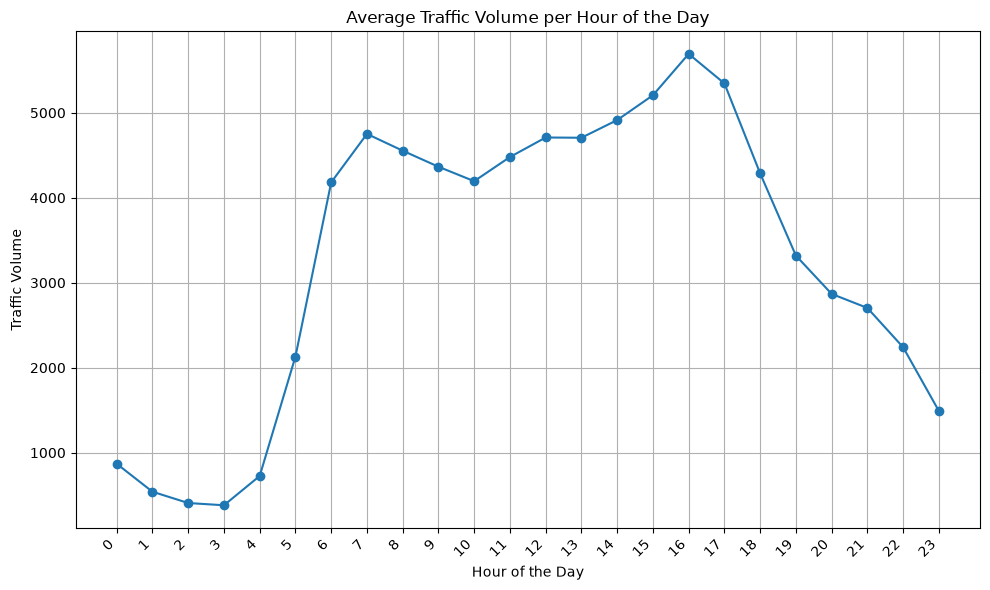

In [6]:

fig, ax = plt.subplots(figsize=(10, 6))

ax.grid()

timestamp = train_df["date"] + pd.to_timedelta(train_df['hr'], unit='h')

# Mean traffic volume per hour of the day
hourly_counts = train_df.groupby("hr")["traffic_volume"].mean()
ax.plot(hourly_counts.index, hourly_counts.values, marker="o")

ax.set_xlabel("Hour of the Day")
ax.set_ylabel("Traffic Volume")
ax.set_title("Average Traffic Volume per Hour of the Day")

plt.xticks(hourly_counts.index)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


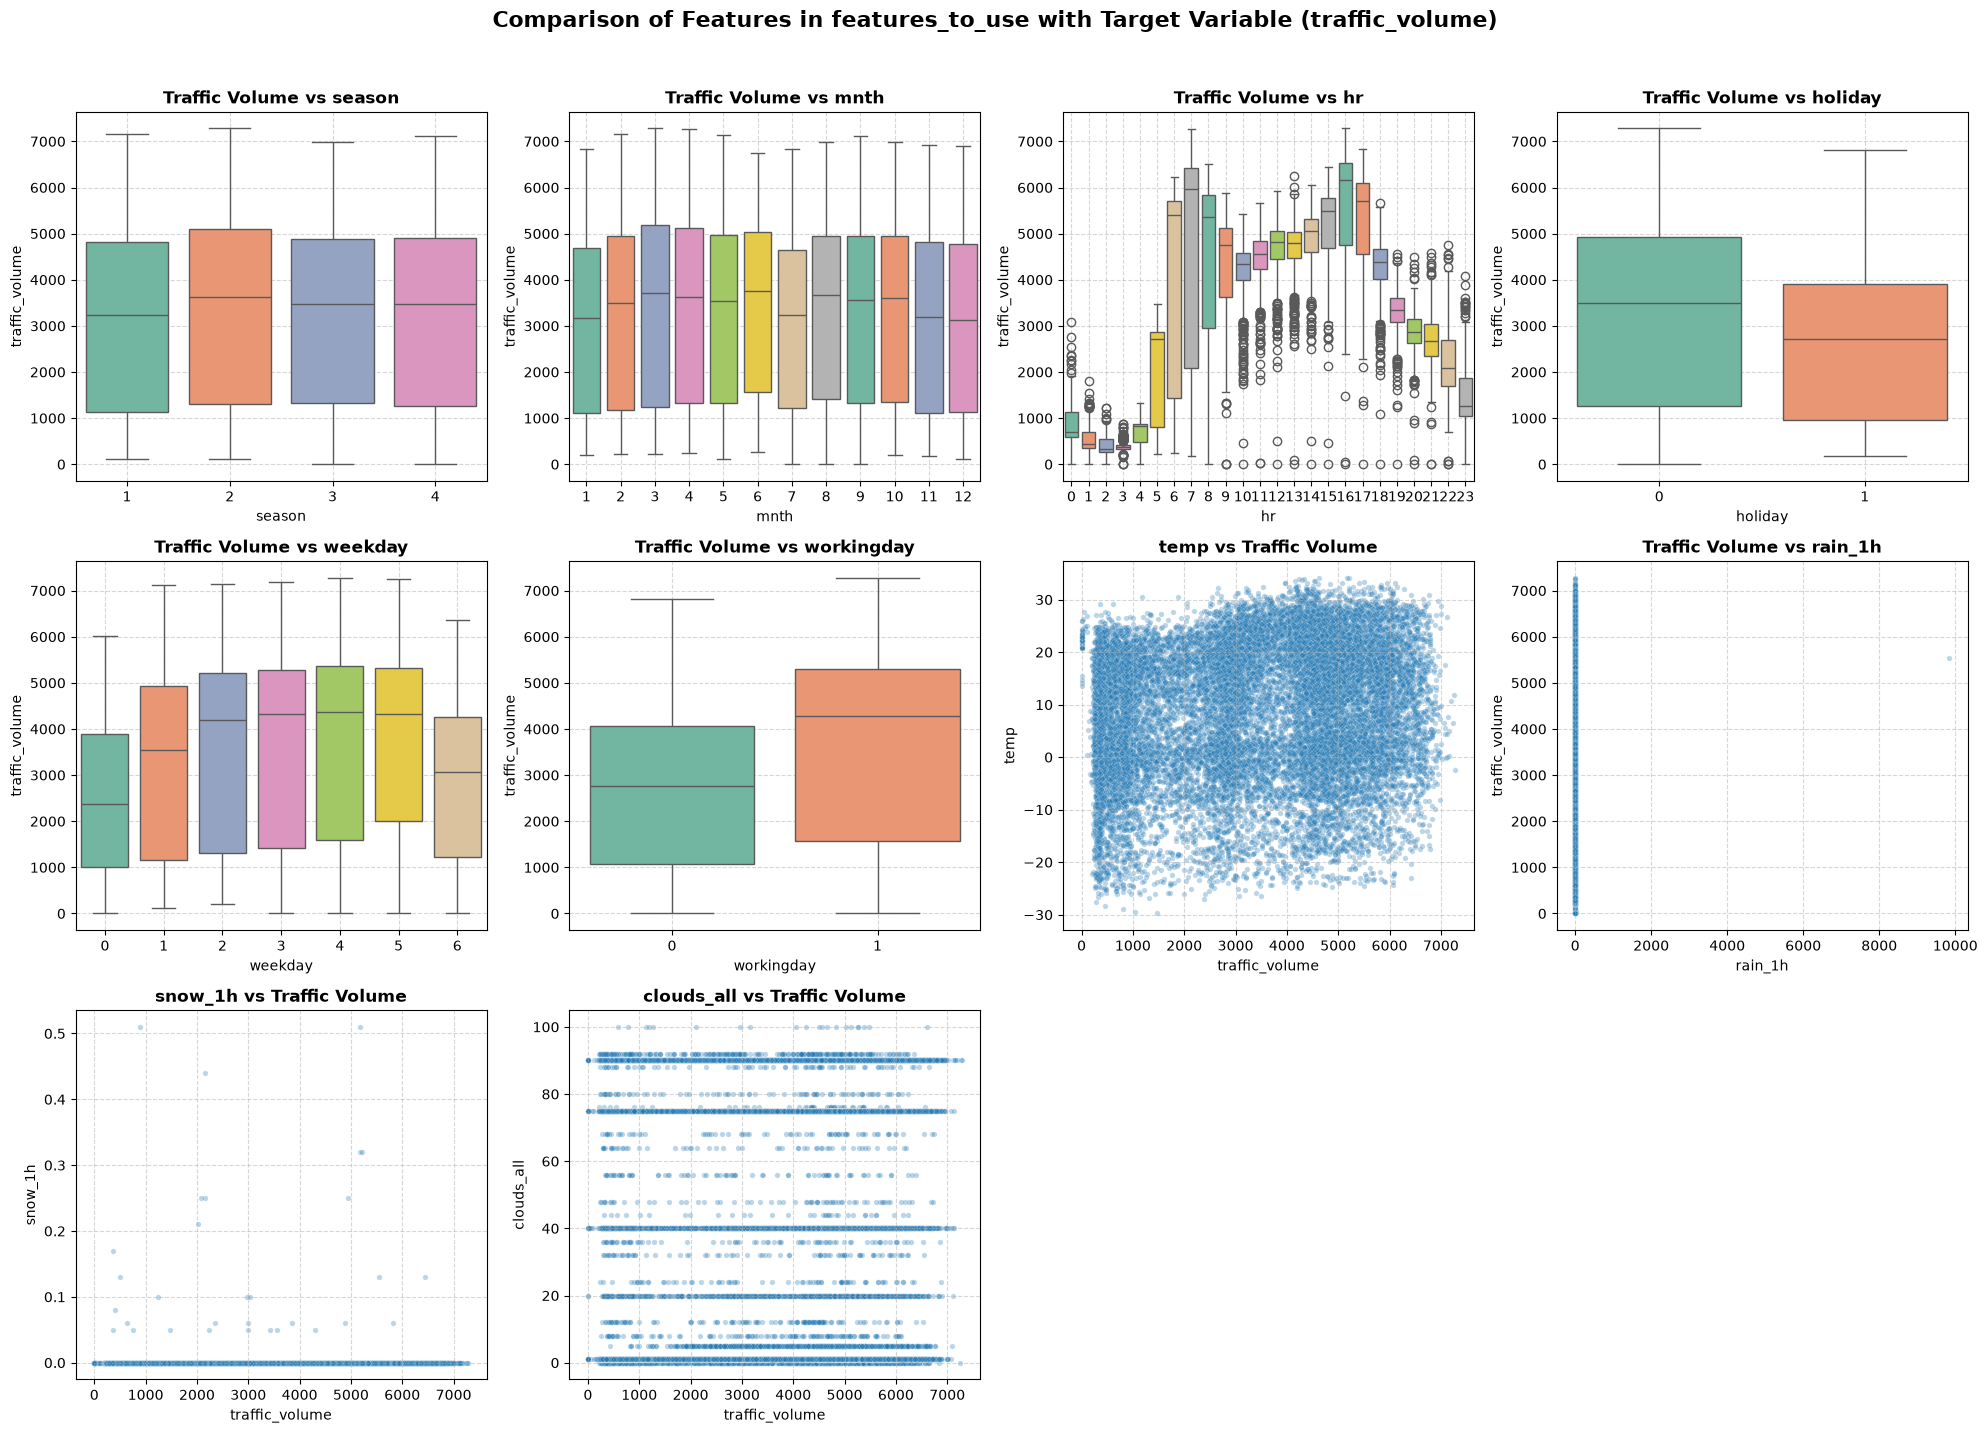

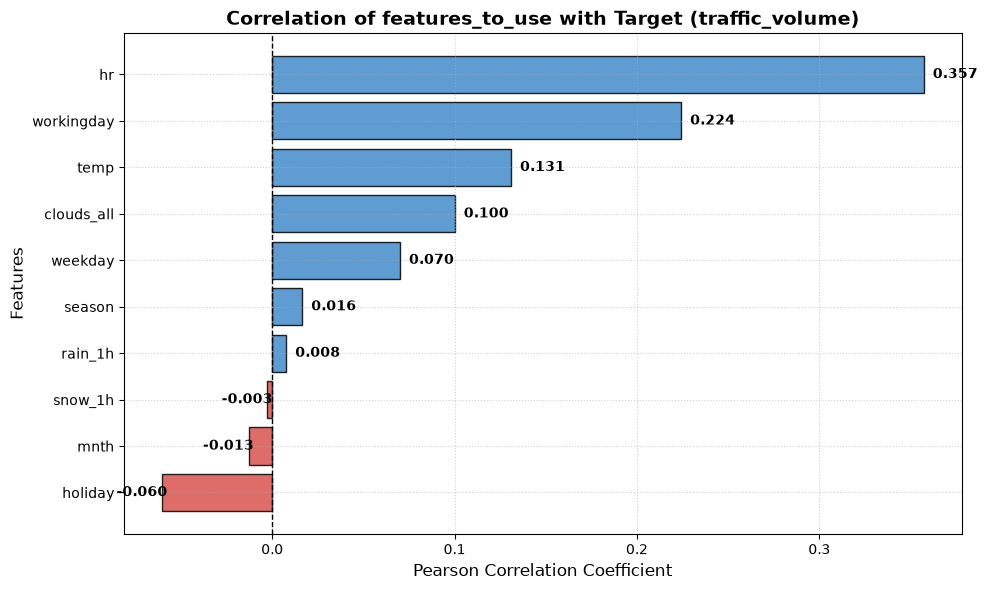

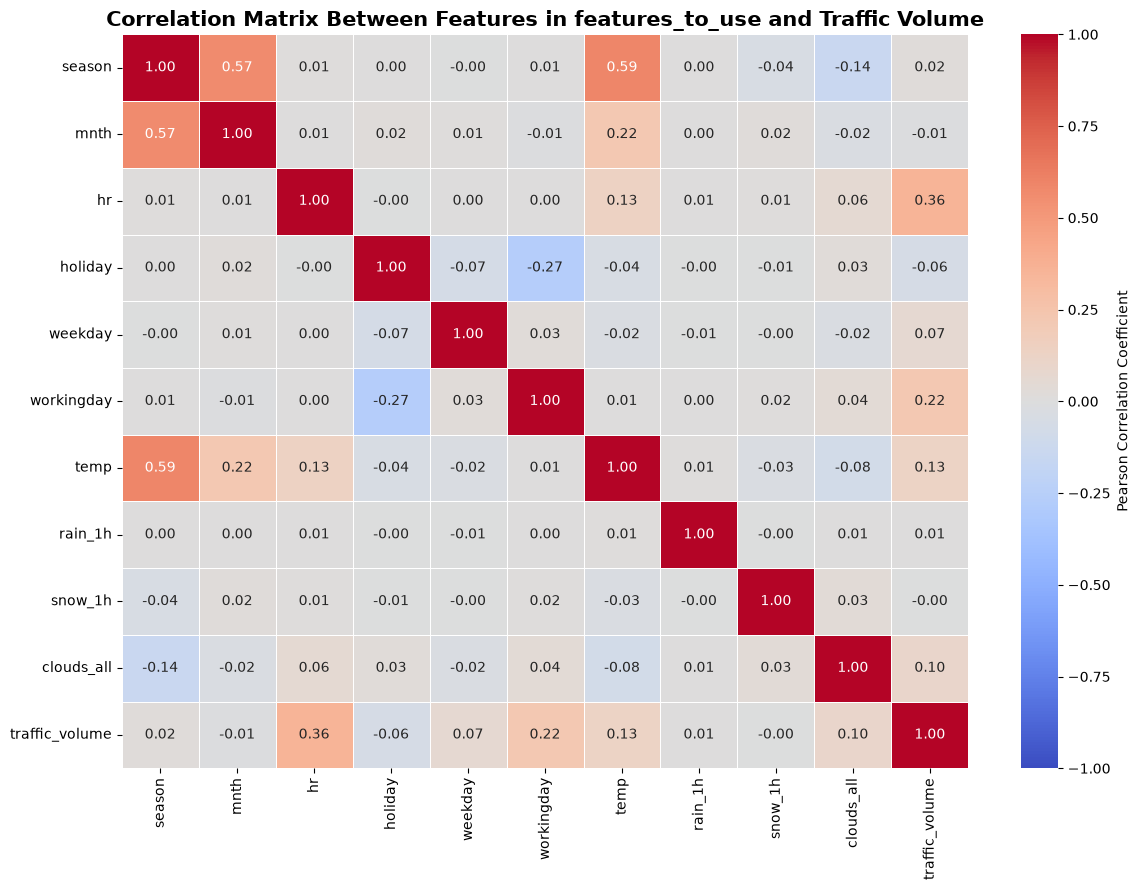

In [7]:
# Other visualizations here, e.g., histograms, boxplots, scatter plots, heatmaps, etc.
# Find the ones that you think are more interesting and relevant to understand the
# data and the problem at hand.

features_to_use = ['season', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'temp', 'rain_1h', 'snow_1h', 'clouds_all']
import seaborn as sns

# 2. Create a 3x4 grid of subplots (12 subplots total for 11 features)
fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(20, 14))
axes = axes.flatten()
# 3. Plot each feature against the target variable traffic_volume
for i, col in enumerate(features_to_use):
    ax = axes[i]
    
    if col in ['temp', 'snow_1h', 'clouds_all']:
        # traffic_volume on the X-axis, feature on the Y-axis
        sns.scatterplot(data=train_df, x='traffic_volume', y=col, ax=ax, alpha=0.3, s=15, color='tab:blue')
        ax.set_title(f'{col} vs Traffic Volume', fontsize=12, fontweight='bold')
    elif col == 'rain_1h':
        # Scatter plot for rain_1h vs traffic_volume
        sns.scatterplot(data=train_df, x=col, y='traffic_volume', ax=ax, alpha=0.3, s=15, color='tab:blue')
        ax.set_title(f'Traffic Volume vs {col}', fontsize=12, fontweight='bold')
    else:
        # Categorical / Discrete features: Box plot vs traffic_volume
        sns.boxplot(data=train_df, x=col, y='traffic_volume', ax=ax, palette='Set2', hue=col, legend=False)
        ax.set_title(f'Traffic Volume vs {col}', fontsize=12, fontweight='bold')
        if col == 'weather':
            ax.tick_params(axis='x', rotation=45)
            
    ax.grid(True, linestyle='--', alpha=0.5)
# 4. Remove the unused 12th subplot
for j in range(len(features_to_use), len(axes)):
    fig.delaxes(axes[j])
plt.suptitle('Comparison of Features in features_to_use with Target Variable (traffic_volume)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 2. Select numeric features from features_to_use
numeric_features = [
    col for col in features_to_use 
    if col in train_df.columns and pd.api.types.is_numeric_dtype(train_df[col])
]
# 3. Compute Pearson correlation with traffic_volume
traffic_corr = train_df[numeric_features + ['traffic_volume']].corr()['traffic_volume'].drop('traffic_volume').sort_values(ascending=True)
# 4. Plot horizontal bar chart
plt.figure(figsize=(10, 6))
colors = ['#d9534f' if val < 0 else '#428bca' for val in traffic_corr.values]
bars = plt.barh(traffic_corr.index, traffic_corr.values, color=colors, edgecolor='black', alpha=0.85)
# Add text values next to each bar
for bar in bars:
    width = bar.get_width()
    offset = 0.005 if width >= 0 else -0.025
    plt.text(width + offset, bar.get_y() + bar.get_height() / 2, f'{width:.3f}', 
             va='center', fontsize=10, fontweight='bold')
plt.axvline(0, color='black', linewidth=1, linestyle='--')
plt.title('Correlation of features_to_use with Target (traffic_volume)', fontsize=14, fontweight='bold')
plt.xlabel('Pearson Correlation Coefficient', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# ==============================================================================
# PLOT 2: Correlation Matrix Heatmap between features_to_use and traffic_volume
# ==============================================================================
numeric_features = [
    col for col in features_to_use 
    if col in train_df.columns and pd.api.types.is_numeric_dtype(train_df[col])
]
cols_for_corr = numeric_features + ['traffic_volume']
corr_matrix = train_df[cols_for_corr].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation Coefficient'}
)
plt.title('Correlation Matrix Between Features in features_to_use and Traffic Volume', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()



> **Question:**
> 
> How did the visualization help in understanding the data?
> Which questions were answered and what hypothesis are left to be tested? 
> 
> Have you decided to remove some feature from the dataset? Why?

Visualizing the data helpes us to see visual relationships between the features and the target variable and helped us discard some more features.

After seing the plots we can clearly see that the hypotesis about "rain_1h" and "snow_1h" were correct: they have a lot of missing values and all of "rain_1h"'s values are 0 ( except one outlier ), so we are not going to use the "rain_1h" feature.

We can also see what features most describe the changes in the traffic volume, with the far winner being "hr", but we can also see that other features carry signal in them: "season", "mnth", "holiday"(strong), "workingday" (strong), "weekday" (strong), "weather" (strong), "clouds_all".

Correlation between features: we can also see that mnth, temp and season are somewhat correlated, but not enough to discard one or two of these features.

----
### **Preprocessing**
(1.0 point) Now that you have a deeper insight about the problem, let's preprocess
the raw data with the necessary transformations and turn the data into an array,
ready to be fed into a model.

Create a function `preprocess_data` and make all required transformation, the
output must be a tuple (X, y) of numpy arrays, where X has shape (n_samples, n_features)
and y is a column array of shape (n_samples,).

Note that the distributions on the features in the test set may not coincide
with the ones in the train set, your preprocessing must take that into account
without peeking at test samples.

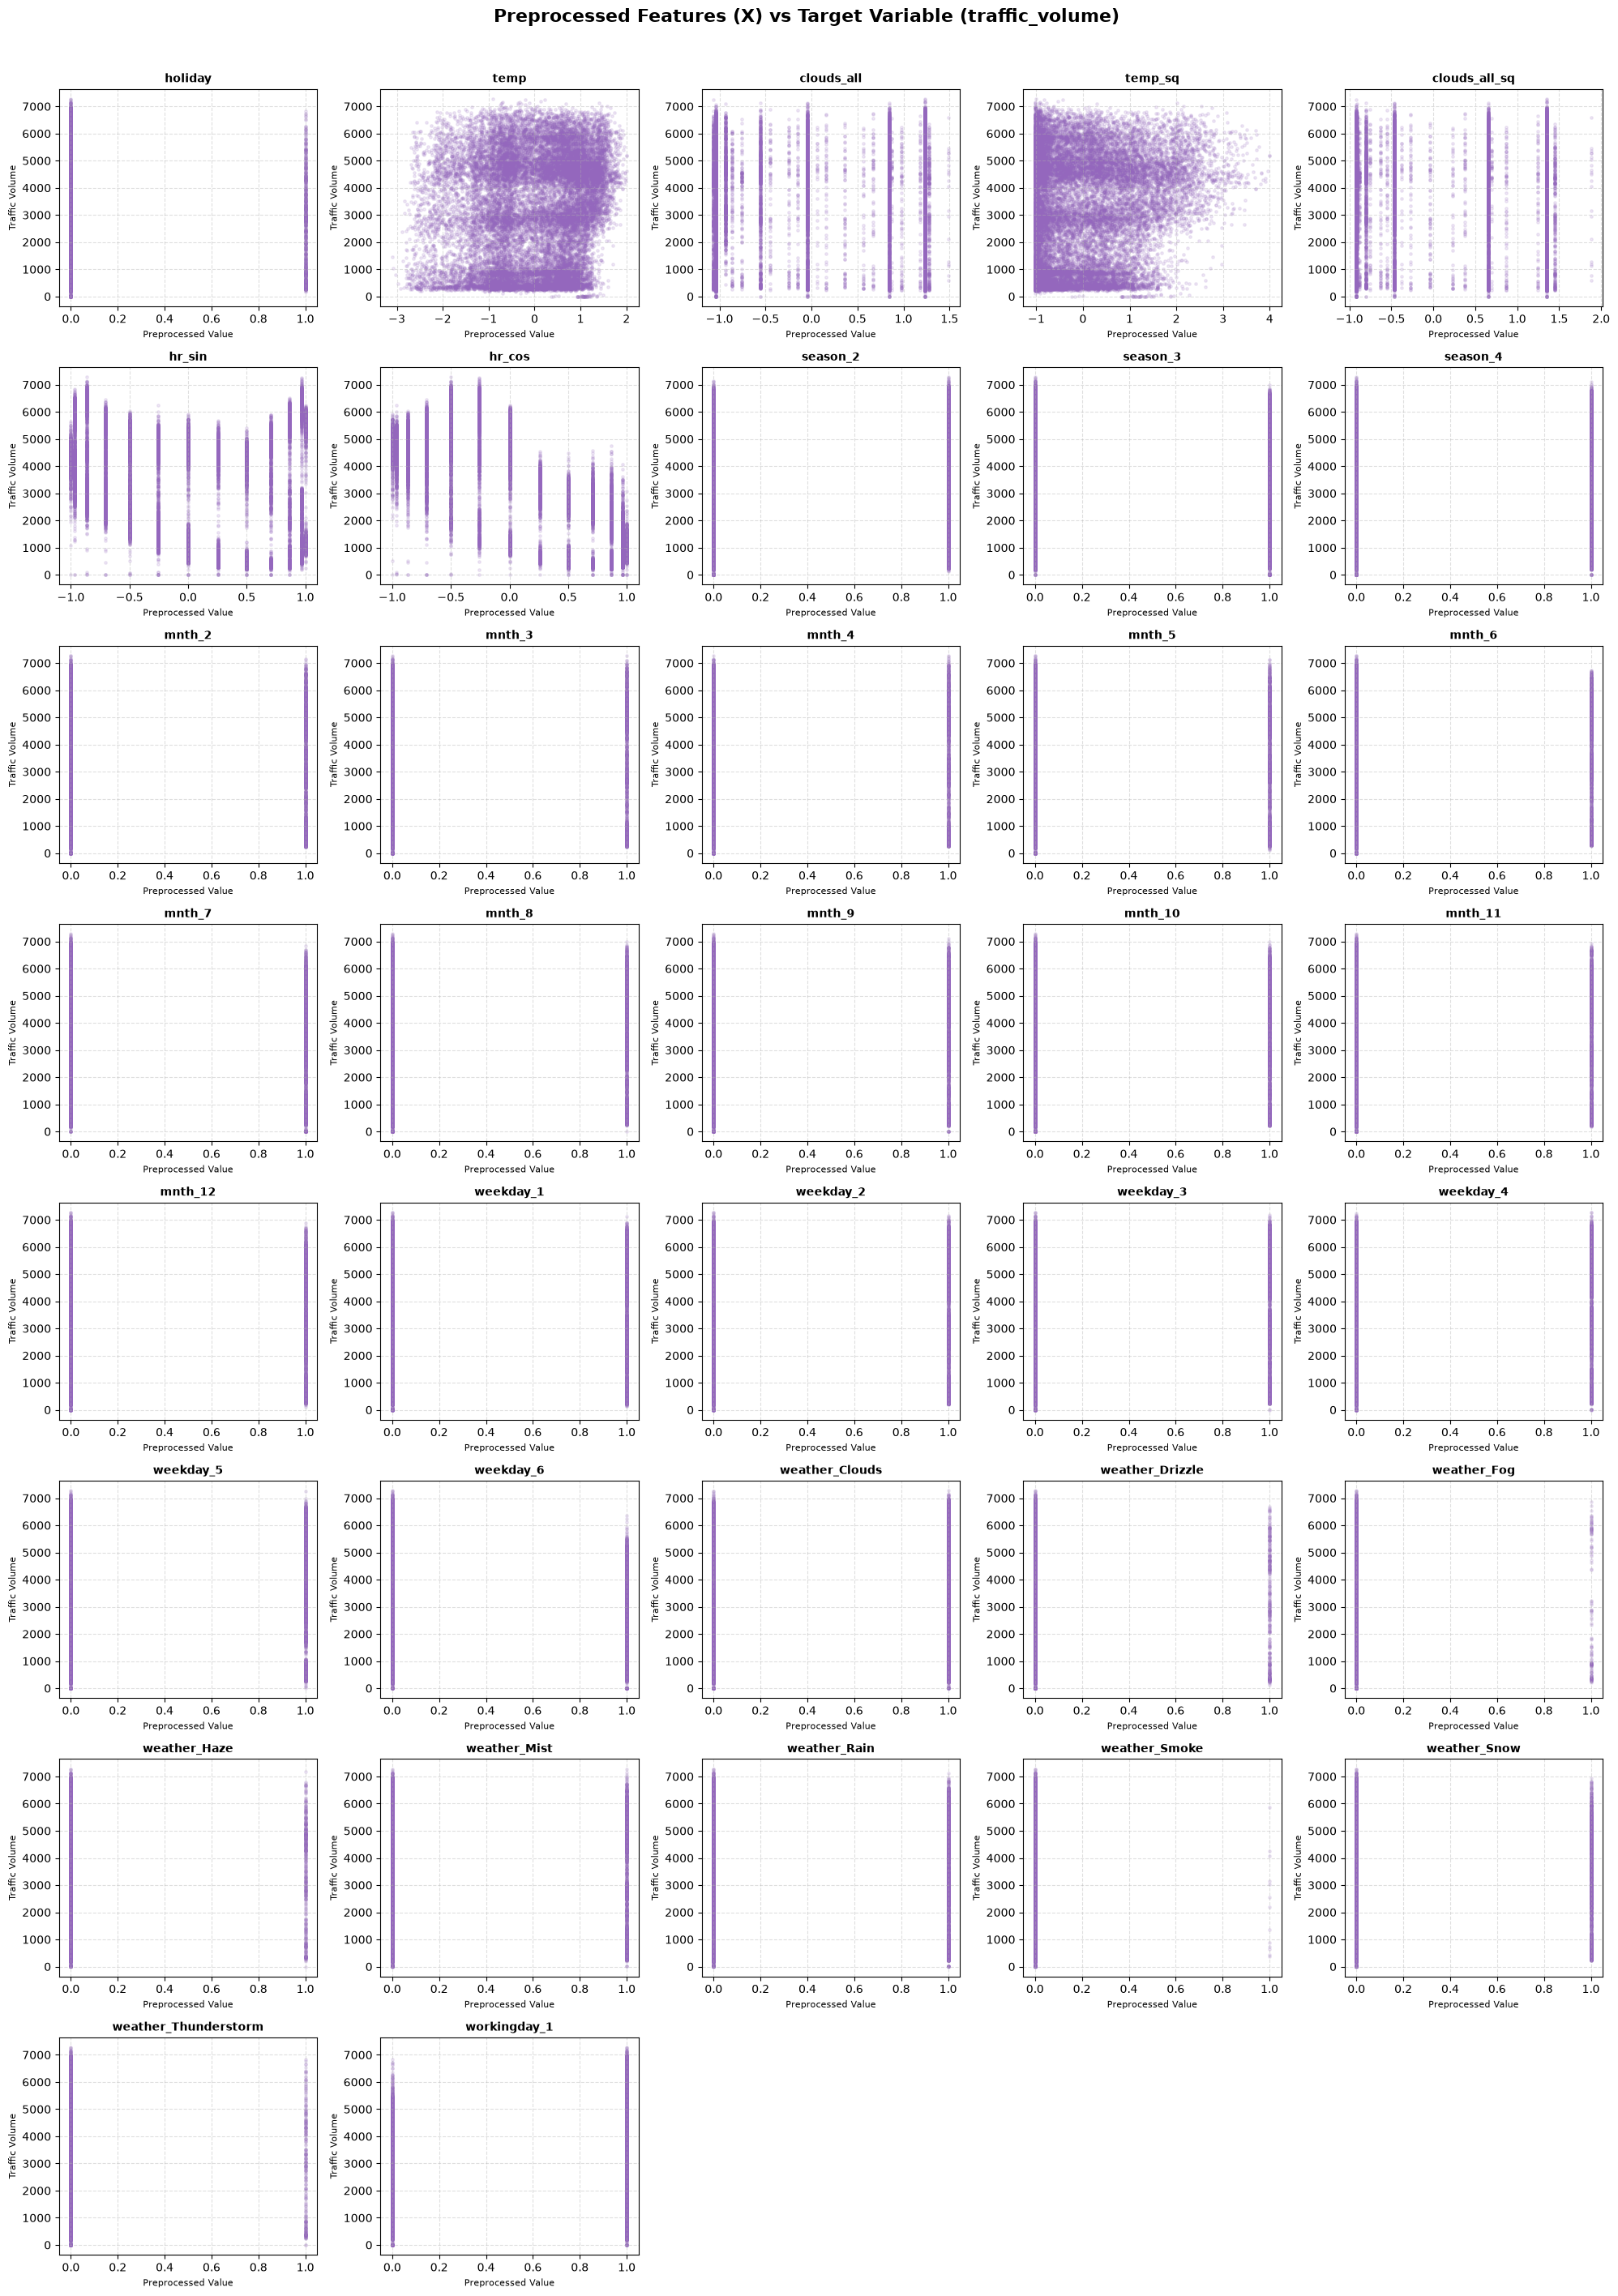

In [8]:
'''
1) add the squared values of features clouds_all, temp
2) handle missing values from features
3) normalize the numeric variables ( zscore ) (clouds_all, temp, clouds_all^2, temp^2) (), but not the label
4) one hot enconding in features season, mnth, weekday, weather, workingday
5) cyclical encoding for hr
the statistics need to be saved to later be applied to test_data
'''

features_to_use = ['hr','season','mnth','holiday','workingday','weekday','weather', 'tmp',' clouds_all']

PREPROCESSING_STATS: dict = {}
def preprocess_data(
    df: pd.DataFrame, 
    is_train: bool | None = None
) -> tuple[NDArray[np.float64], NDArray[np.float64]]:
    global PREPROCESSING_STATS
    """
    Preprocesses the raw dataset according to the pipeline:
    1. Selects specified features_to_use.
    2. Handles missing values.
    3. Adds squared values of continuous features (temp^2, clouds_all^2).
    4. Applies cyclical sine/cosine encoding for 'hr'.
    5. One-hot encodes 'season', 'mnth', 'weekday', 'weather', and 'workingday'.
    6. Applies Z-score normalization to numeric features (temp, clouds_all, temp^2, clouds_all^2).
    7. Saves training statistics to transform test data without data leakage.
    """
    
    # Automatically determine if fitting (training) or transforming (testing)
    if is_train is None:
        is_train = len(PREPROCESSING_STATS) == 0 or len(df) > 10000
    data = df.copy()
    # Specified features to use
    features_to_use = [
        'hr', 'season', 'mnth', 'holiday', 'workingday', 
        'weekday', 'weather', 'temp', 'clouds_all'
    ]
    
    target_col = 'traffic_volume'
    cols_to_select = [c for c in features_to_use if c in data.columns]
    if target_col in data.columns:
        cols_to_select.append(target_col)
        
    data = data[cols_to_select]
    num_cols = ['temp', 'clouds_all']
    cat_cols = ['season', 'mnth', 'weekday', 'weather', 'workingday']
    # 1. Handle missing values
    if is_train:
        PREPROCESSING_STATS = {}  # Reset stats when fitting training data
        PREPROCESSING_STATS['num_impute'] = {c: data[c].median() for c in num_cols if c in data.columns}
        PREPROCESSING_STATS['cat_impute'] = {c: data[c].mode()[0] for c in cat_cols + ['holiday', 'hr'] if c in data.columns}
    for c in num_cols:
        if c in data.columns:
            data[c] = data[c].fillna(PREPROCESSING_STATS['num_impute'][c])
    for c in cat_cols + ['holiday', 'hr']:
        if c in data.columns:
            data[c] = data[c].fillna(PREPROCESSING_STATS['cat_impute'][c])
    # 2. Add squared values of continuous features: temp^2, clouds_all^2
    data['temp_sq'] = data['temp'] ** 2
    data['clouds_all_sq'] = data['clouds_all'] ** 2
    # 3. Cyclical encoding for 'hr'
    data['hr_sin'] = np.sin(2 * np.pi * data['hr'] / 24.0)
    data['hr_cos'] = np.cos(2 * np.pi * data['hr'] / 24.0)
    data = data.drop(columns=['hr'])
    # 4. One-Hot Encoding for season, mnth, weekday, weather, workingday
    if 'holiday' in data.columns:
        data['holiday'] = data['holiday'].astype(int)
        
    data = pd.get_dummies(data, columns=[c for c in cat_cols if c in data.columns], drop_first=True, dtype=float)
    # Separate target variable (y) from feature matrix (X)
    if target_col in data.columns:
        y = data[target_col].values.astype(np.float64)
        X_df = data.drop(columns=[target_col])
    else:
        y = np.array([])
        X_df = data
    # Align columns to guarantee identical feature schema between train and test
    if is_train:
        PREPROCESSING_STATS['feature_cols'] = X_df.columns.tolist()
    else:
        X_df = X_df.reindex(columns=PREPROCESSING_STATS['feature_cols'], fill_value=0.0)
    # 5. Z-score Normalization (temp, clouds_all, temp^2, clouds_all^2) - Label (y) is NOT normalized
    z_cols = ['temp', 'clouds_all', 'temp_sq', 'clouds_all_sq']
    if is_train:
        PREPROCESSING_STATS['z_mean'] = X_df[z_cols].mean()
        PREPROCESSING_STATS['z_std'] = X_df[z_cols].std().replace(0, 1.0)
    X_df[z_cols] = (X_df[z_cols] - PREPROCESSING_STATS['z_mean']) / PREPROCESSING_STATS['z_std']
    X = X_df.values.astype(np.float64)
    return X, y



# aqui é apenas um teste de plotting:

# 1. Call preprocess_data to transform train_df into feature matrix X and target array y
X, y = preprocess_data(train_df)
# 2. Retrieve preprocessed feature names from PREPROCESSING_STATS
feature_names = PREPROCESSING_STATS.get('feature_cols', [f'feature_{i}' for i in range(X.shape[1])])
n_features = X.shape[1]
# 3. Configure grid layout (5 columns per row)
n_cols = 5
n_rows = (n_features + n_cols - 1) // n_cols
fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(20, 3.5 * n_rows))
axes = axes.flatten()
# 4. Plot each preprocessed feature column X[:, j] against y (traffic_volume)
for j in range(n_features):
    ax = axes[j]
    ax.scatter(X[:, j], y, alpha=0.15, s=6, color='tab:purple')
    ax.set_title(feature_names[j], fontsize=10, fontweight='bold')
    ax.set_xlabel('Preprocessed Value', fontsize=8)
    ax.set_ylabel('Traffic Volume', fontsize=8)
    ax.grid(True, linestyle='--', alpha=0.4)
# 5. Hide unused subplots in the grid
for k in range(n_features, len(axes)):
    fig.delaxes(axes[k])
plt.suptitle('Preprocessed Features (X) vs Target Variable (traffic_volume)', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

---

## **Linear Regression**

Linear regression is a simple model that assumes a linear relationship between
the observed features and the target.
Specifically, given an observation $(x_1, x_2, \dots, x_n)$, we assume there exist
a set of weights $\beta_0, \beta_1, \beta_2, \dots, \beta_n$ such that

$$y \approx \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_n x_n.$$

Each weight $\beta_i$ measures the marginal contribution of $x_i$ to the
prediction while keeping other variables fixed.
The model assumes additive effects, meaning the influence of multiple variables
is the sum of their individual contributions unless interaction terms are
explicitly included.

For example, if raining decreases the traffic volume, but the morning rush hour
increases it, a rainy rush hour contribution is no different than the contribution
of rainy plus the contribution of the rush hour.

We can estimate the weights $\beta_i$ by measuring a discrepancy score between
predicted values $\hat{y}$ obtained with some weight $\beta$ and the ground-truth
value $y$, and minimizing this score.

A natural way to achieve this is by defining a distance between targets that is
differentiable. However, choosing a distance that is statistical relevant is not
trivial. Instead, we could measure what is the probability that, when given
a sample $x$ and a current weight $\beta$, the ground-truth $y$ is observed, *i.e.*

$$p(y \mid x, \beta).$$

This measures what is the probability of the ground-truth given that the model
with weights $\beta$ is the true estimator.

If we tweak the weights $\beta$ so that the probability of all ground-truths is
maximized, we obtain a well-fit model.
This is achieved by the likelihood function, under the assumption of independent
samples in the dataset.

$$\mathcal{L}(\beta) = \prod_{i=1}^n p(y^i \mid x^i, \beta).$$

Indicating that an estimator $\beta$ is only good if the ground-truth probabilities
are high across all the samples. As this criteria can be very small due to the
multiplication of small quantities, a common trick is to use the log likelihood
function instead, using the log properties,

$$\log \mathcal{L}(\beta) = \sum_{i=1}^n \log p(y^i \mid x^i, \beta),$$
and then minimizing $-\log \mathcal{L}(\beta)$.

This method is called Maximum Likelihood Estimation (MLE) and it is a very commonly
used estimator in Machine Learning, as we are going to see.

### **Gaussian assumption**
We cannot directly measure $p(y \mid x, \beta)$ at the moment, as we do not have
a probability distribution that links $y$ with $x$ and $\beta$ yet, but a
deterministic relationship (linear).

To introduce this probabilistic aspect, we can suppose that the approximation
between the ground-truth $y$ and the linear term $\hat{y} = \beta_0 + \beta_1 x_1 + \dots$
is only wrong by an unpredictable "error" $\epsilon$, also called a *residual*.
A common way of introducing this error is by supposing that $\epsilon$ comes from
a zero-centered normal (or Gaussian) distribution,
*i.e.* $\epsilon \sim \mathcal{N}(0, \sigma^2)$.

The relationship between $y$, $x$ and $\beta$ are now intermediated by $\epsilon$,

$$y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_n x_n + \epsilon.$$

This makes $y$ to be a random variable centered at our linear predicition, deviated
by a random quantity, with fixed standard deviation $\sigma$ (homoscedastic).
This assumption is called **Gaussian assumption**, and has interesting properties
that intersect with the Ordinary Least Squares method, including the criterion.

With this assumption, we can measure $p(y \mid x, \beta)$ directly using the
Normal probability distribution function

$$p(y \mid x, \beta) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left(- \frac{(y - x^T\beta)^2}{2\sigma^2}\right),$$

$$\log p(y \mid x, \beta) =  - \frac{(y - x^T\beta)^2}{2\sigma^2} - \log(\sqrt{2\pi\sigma^2}).$$

Thus, minimizing $-\log \mathcal{L}(\beta)$, yield to

$$-\log \mathcal{L}(\beta) \propto \sum_{i=1}^n (y^i - {x^i}^T\beta)^2 = \sum_{i=1}^n (y^i - \hat{y}^i)^2 $$

Which is equivalent to the Mean Squared Error (MSE) criterion.

### **Implementation**

(0.5 points) Under the statistical lens of Linear Regression, we have also
derived the same loss function as ordinary least squares method. Now it's time to
implement the `fit` method using **gradient descent** without using any machine
learning library.


Also, complete the following metric functions with their implementations and run
your model for different learning rates

In [9]:
def mse(y_true: NDArray[np.float64], y_pred: NDArray[np.float64]) -> float:
    """
    Calculates the Mean Squared Error (MSE) between true and predicted target values.
    MSE = (1/N) * sum((y_true - y_pred)^2)
    """
    return float(np.mean((y_true - y_pred) ** 2))

def r2_score(y_true: NDArray[np.float64], y_pred: NDArray[np.float64]) -> float:
    """
    Calculates the R² score (Coefficient of Determination) between true and predicted values.
    R² = 1 - (SS_res / SS_tot)
    """
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return float(1.0 - (ss_res / (ss_tot + 1e-12)))

def mae(y_true: NDArray[np.float64], y_pred: NDArray[np.float64]) -> float:
    """
    Calculates the Mean Absolute Error (MAE) between true and predicted values.
    MAE = (1/N) * sum(|y_true - y_pred|)
    """
    return float(np.mean(np.abs(y_true - y_pred)))

# You can implement other metrics if you want, for example
# - Mean Absolute Percentage Error (MAPE)
# - Root Mean Squared Error (RMSE)
# - Explained Variance Score
# - etc.

class LinearRegression:
    def __init__(
        self,
        learning_rate: float = 0.01,
        n_iterations: int = 1000,
    ) -> None:
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.weights: NDArray[np.float64] | None = None
        self.bias: float | None = None
    def fit(self, X: NDArray[np.float64], y: NDArray[np.float64]) -> None:
        """
        Trains the Linear Regression model using Gradient Descent.
        Loss function: MSE = (1/N) * sum((X*w + b - y)^2)
        Gradients:
            dw = (2/N) * X^T * (y_pred - y)
            db = (2/N) * sum(y_pred - y)
        """
        n_samples, n_features = X.shape
        weights = np.zeros(n_features, dtype=np.float64)
        bias = 0.0
        for _ in range(self.n_iterations):
            y_pred = np.dot(X, weights) + bias
            error = y_pred - y
            
            # Gradients of MSE loss
            dw = (2.0 / n_samples) * np.dot(X.T, error)
            db = (2.0 / n_samples) * np.sum(error)
            # Update parameters
            weights -= self.learning_rate * dw
            bias -= self.learning_rate * db
        self.weights = weights
        self.bias = bias
    def predict(self, X: NDArray[np.float64]) -> NDArray[np.float64]:
        """
        Makes predictions using the trained weights and bias.
        y_pred = X * w + b
        """
        assert self.weights is not None and self.bias is not None, "Model is not trained yet"
        return np.dot(X, self.weights) + self.bias

In [10]:
def plot_results(lrs: list[float], performances: dict[str, list[float]]) -> None:
    n_metrics = len(performances)

    fig, ax = plt.subplots(figsize=(5 * n_metrics, 5), ncols=n_metrics)

    for i, (metric_name, metric_values) in enumerate(performances.items()):
        ax[i].plot(lrs, metric_values, marker="o")
        ax[i].set_xlabel("Learning Rate")
        ax[i].set_title(metric_name)
        ax[i].grid()
    
        ax[i].set_xscale("log")

    plt.tight_layout()
    plt.show()

# fiz isso para melhor vizualização em baixo, variando também o numero de learning steps
def plot_results(lrs: list[float], performances: dict[str, list[float]]) -> None:
    """
    Plots performances in a 3x3 grid:
    - Row 1: 10 iterations (mse, r2, mae)
    - Row 2: 100 iterations (mse, r2, mae)
    - Row 3: 1000 iterations (mse, r2, mae)
    """
    fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15, 12))
    
    iterations = [10, 100, 1000]
    metrics = ["mse", "r2_score", "mae"]
    for row_idx, n_iter in enumerate(iterations):
        for col_idx, metric_base in enumerate(metrics):
            ax = axes[row_idx, col_idx]
            key = f"{metric_base}_{n_iter}"
            
            if key in performances:
                values = performances[key]
                ax.plot(lrs, values, marker="o", linewidth=2, color="tab:blue")
                ax.set_title(key, fontsize=11, fontweight="bold")
                ax.set_xlabel("Learning Rate", fontsize=9)
                ax.set_ylabel(metric_base.upper(), fontsize=9)
                ax.grid(True, linestyle="--", alpha=0.5)
                
                # Apply log scale if learning rates are positive
                if all(lr > 0 for lr in lrs):
                    ax.set_xscale("log")
    plt.suptitle("Model Performance Across Learning Rates & Iteration Steps (3x3 Grid)", fontsize=15, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()

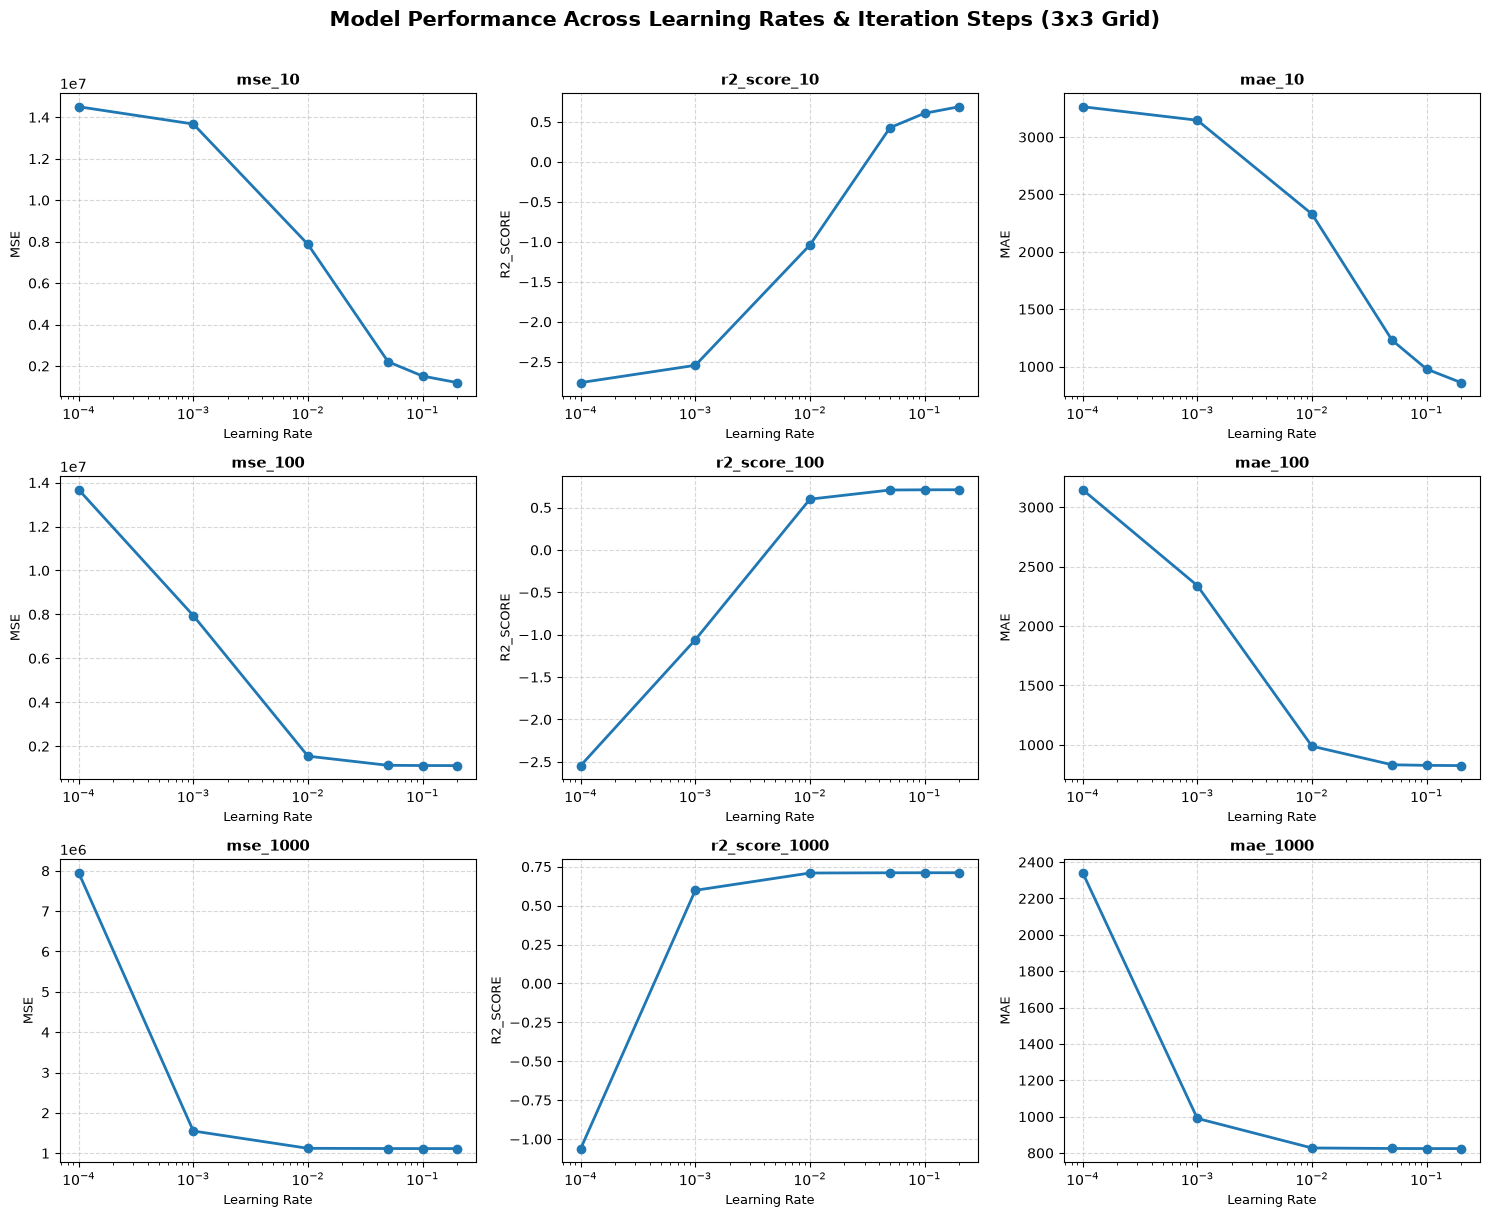

In [11]:
X, y = preprocess_data(train_df)

# You can experiment with a pre-defined set of learning rates or
# with a range of learning rates (e.g. logarithmically spaced)
lrs = [0.0001, 0.001, 0.01, 0.05, 0.1, 0.2]

performances = {
    "mse_10": [],
    "r2_score_10": [],
    "mae_10": [],
    "mse_100": [],
    "r2_score_100": [],
    "mae_100": [],
    "mse_1000": [],
    "r2_score_1000": [],
    "mae_1000": [],
    # Add other metrics here if you implemented them
}
n_iter = [10,100,1000]

for iteration_number in n_iter:
    for lr in lrs:
        model = LinearRegression(learning_rate=lr, n_iterations=iteration_number)
        model.fit(X, y)
        y_pred = model.predict(X)

        mse_score = mse(y, y_pred)
        r2 = r2_score(y, y_pred)
        mae_score = mae(y, y_pred)

        performances[f"mse_{iteration_number}"].append(mse_score)
        performances[f"r2_score_{iteration_number}"].append(r2)
        performances[f"mae_{iteration_number}"].append(mae_score)
        # Add other metrics here if you implemented them

plot_results(lrs, performances)

> **Question:**
>
> How did the model perform for different learning rates?
> What happened when the learning rate was too small or too large?
>
> Interpret the metric values obtained.
Is the prediction error small relative to the scale of the target variable?
>
> Propose at least one hypothesis explaining the observed error.

With the plots we can see that when the learning rate is too small the weights barely update, making the model underfit( high mse, low r2, high mae), when increasing steps, it converges, but it does so way slower than higher learning rates

Optimal Learning Rate (lr = 0.01 to 0.2): The model converges rapidly. With 100 or 1,000 iterations and lr >= 0.01, performance stabilizes at the best values.

Prediction Error: MAE approx. 824 vehicles/hour represents an average error of about 25% relative to the mean traffic volume. This error is moderate—not tiny, but reasonable for a simple linear model baseline.

Variance Explained: R^2 approx. 0.75 indicates that the model explains 75% of the total variance in traffic volume.


---
### **Visualizing Predictions**

(1.0 points) Numerical metrics summarize model quality, but visual diagnostics reveal structural problems that scalar measures may hide. Two standard visual tools are the predicted vs. observed plot and the Q–Q plot of residuals.

Choose a model from the previous session to analyse further here.

#### **Predicted vs. Observed Plot**

A direct way to evaluate prediction quality is to compare the predicted values with the true observations.
For each sample, plot the pair `(y, y_pred)`, the ideal predictor would have
perfectly match predictions, yielding all points in the line y = x in the graph.

However, this is often not the case, as prediction can go wrong.
This plot help us interpret points that are closer to the x=y line as better
predictions, and points further from this line as bad predictions.

If the overall shape of the points does not follow the line, we may have a
**systematic error**, indicating model misspecification.

By coloring each point by some other characteristic, we can also see if the error
is systematic with respect to that characteristic.
For example, the model mispredicts some seasons more than others.

You can explore more plots to get an insight on why and how is your model fit.

In [12]:
def pred_vs_true_plot(y_true: NDArray[np.float64], y_pred: NDArray[np.float64]) -> None:
    _, ax = plt.subplots(figsize=(10, 6))

    ax.grid()
    ax.scatter(y_true, y_pred, alpha=0.5)
    ax.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], color='red', linestyle='--', label='Ideal Fit')
    ax.set_xlabel("True Values")
    ax.set_ylabel("Predicted Values")
    ax.set_title("Predicted vs True Values")
    ax.legend()
    plt.show()

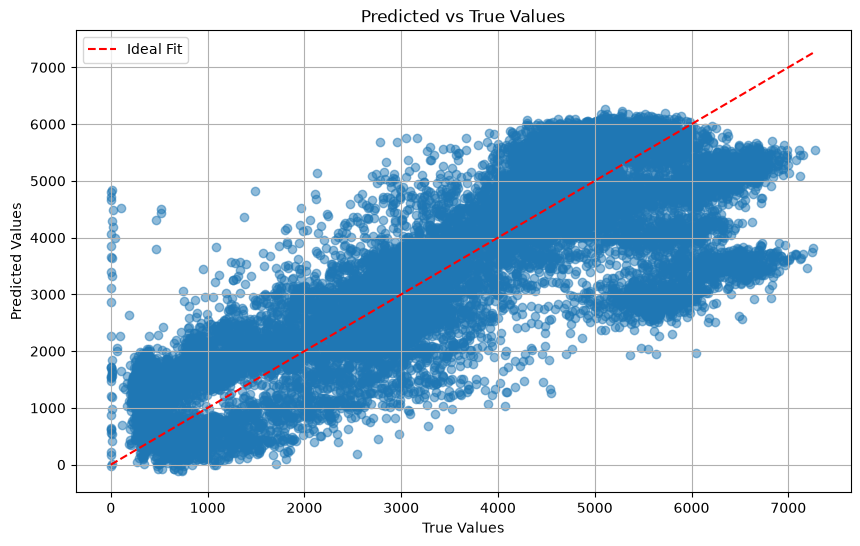

In [13]:
best_lr = 0.1 # Choose the best learning rate based on the previous graphs

best_linear_model = LinearRegression(learning_rate=best_lr, n_iterations=10000)
best_linear_model.fit(X, y)
y_pred = best_linear_model.predict(X)

pred_vs_true_plot(y, y_pred)

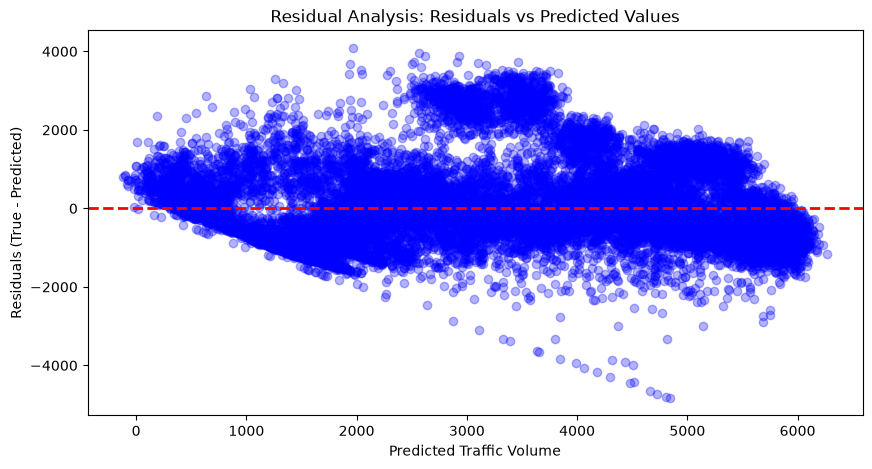

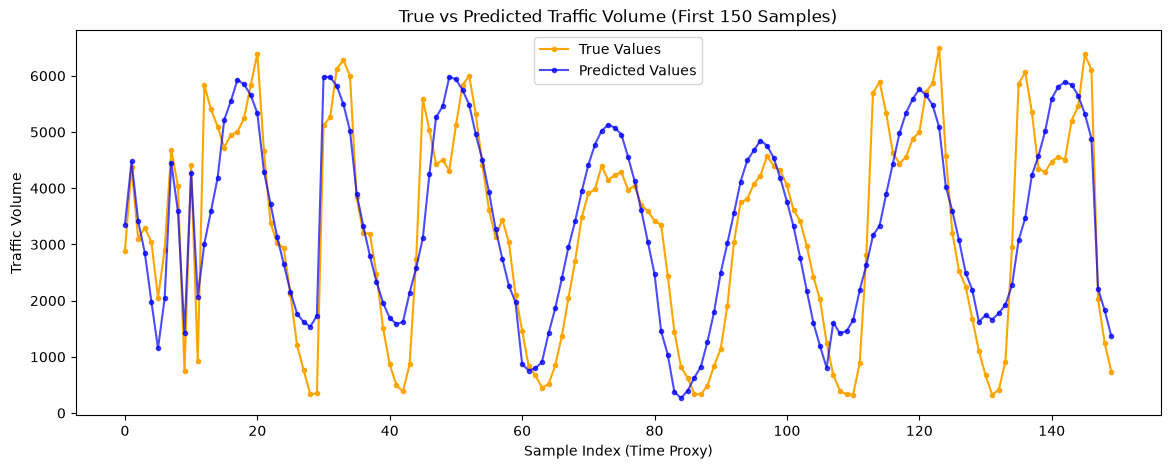

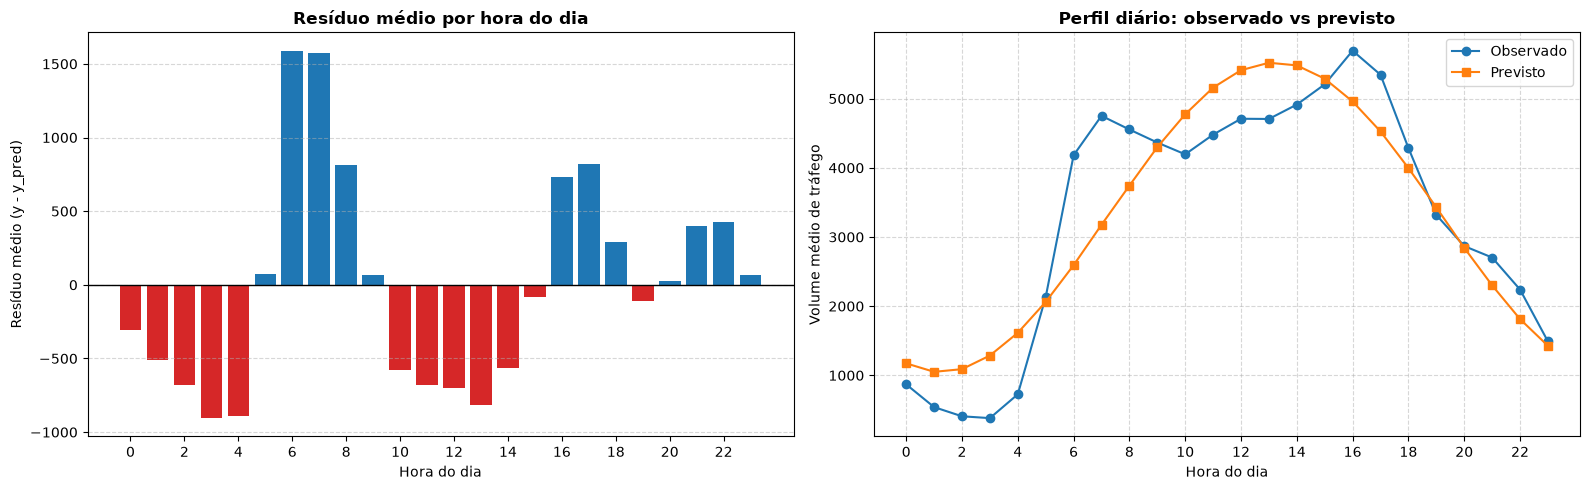

Previsões negativas: 16 (0.07%), mínimo = -120
Assimetria dos resíduos: +0.949  (0.0 = simétrico)
Curtose dos resíduos:    3.955  (3.0 = normal)


In [14]:
# Explore more plots to analyze the predictions, e.g., predictions vs time, contribution of each feature to the predictions, etc.

y_true_arr = np.array(train_df['traffic_volume'])  
y_pred_arr = np.array(y_pred) 
residuals = y_true_arr - y_pred_arr

# 1. Gráfico de Resíduos vs Valores Previstos
plt.figure(figsize=(10, 5))
plt.scatter(y_pred_arr, residuals, alpha=0.3, color='blue')
plt.axhline(y=0, color='red', linestyle='--', linewidth=2)
plt.xlabel('Predicted Traffic Volume')
plt.ylabel('Residuals (True - Predicted)')
plt.title('Residual Analysis: Residuals vs Predicted Values')
plt.show()

# 2. Gráfico de Previsões vs Realidade em uma amostra sequencial (ex: 150 primeiras instâncias)
plt.figure(figsize=(14, 5))
plt.plot(y_true_arr[:150], label='True Values', color='orange', marker='.')
plt.plot(y_pred_arr[:150], label='Predicted Values', color='blue', alpha=0.7, marker='.')
plt.xlabel('Sample Index (Time Proxy)')
plt.ylabel('Traffic Volume')
plt.title('True vs Predicted Traffic Volume (First 150 Samples)')
plt.legend()
plt.show()

# 3. Onde, exatamente, o erro se concentra?
# O gráfico 2 já sugere que o modelo não acompanha os picos diários. Agregar o
# resíduo por hora do dia transforma essa impressão visual em número.
hr_train = train_df["hr"].to_numpy()

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 5))

# (a) Resíduo médio por hora do dia.
# Se o modelo estivesse bem especificado, esta curva seria ~0 em todas as horas.
ax = axes[0]
mean_res = np.array([residuals[hr_train == h].mean() for h in range(24)])
ax.bar(range(24), mean_res, color=np.where(mean_res < 0, "tab:red", "tab:blue"))
ax.axhline(0, color="black", lw=1)
ax.set_xlabel("Hora do dia")
ax.set_ylabel("Resíduo médio (y - y_pred)")
ax.set_title("Resíduo médio por hora do dia", fontweight="bold")
ax.set_xticks(range(0, 24, 2))
ax.grid(axis="y", ls="--", alpha=0.5)

# (b) Perfil diário observado vs previsto: mostra o que o modelo consegue representar.
ax = axes[1]
ax.plot(range(24), [y_true_arr[hr_train == h].mean() for h in range(24)],
        marker="o", label="Observado")
ax.plot(range(24), [y_pred_arr[hr_train == h].mean() for h in range(24)],
        marker="s", label="Previsto")
ax.set_xlabel("Hora do dia")
ax.set_ylabel("Volume médio de tráfego")
ax.set_title("Perfil diário: observado vs previsto", fontweight="bold")
ax.set_xticks(range(0, 24, 2))
ax.legend()
ax.grid(ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

n_neg = int((y_pred_arr < 0).sum())
skew = float(((residuals - residuals.mean()) ** 3).mean() / residuals.std() ** 3)
kurt = float(((residuals - residuals.mean()) ** 4).mean() / residuals.std() ** 4)
print(f"Previsões negativas: {n_neg} ({100 * n_neg / len(y_pred_arr):.2f}%), mínimo = {y_pred_arr.min():.0f}")
print(f"Assimetria dos resíduos: {skew:+.3f}  (0.0 = simétrico)")
print(f"Curtose dos resíduos:    {kurt:.3f}  (3.0 = normal)")

> **Question:**
>
> Based on your visualizations, do you observe systematic deviations
(for example curvature or clusters)?
>
> If systematic patterns exist, what do they suggest about the relationship between
the predictors and the target?
>
> Does this visualization support or contradict the hypotheses you proposed earlier?

Sim, e o desvio é fortemente sistemático.

**No gráfico previsto vs observado** a nuvem não acompanha a reta $y = x$: ela é
achatada em torno da média. Para observações com volume real baixo (madrugada,
$y < 1000$) o modelo prevê valores altos demais, e para volumes reais altos
(picos, $y > 5000$) prevê valores baixos demais. Esse achatamento é a assinatura
de um modelo com capacidade insuficiente — ele está prevendo algo próximo da
média condicional grosseira em vez de acompanhar a amplitude real dos dados.

**O resíduo médio por hora deixa isso explícito.** Se o modelo estivesse bem
especificado, essa curva seria ruído em torno de zero. Em vez disso ela oscila
de forma ordenada:

| hora | 3h | 6h | 7h | 13h | 17h |
|---|---|---|---|---|---|
| resíduo médio | −905 | +1589 | +1575 | −813 | +820 |

São erros médios da ordem de ±1500 veículos/hora, com sinal que se alterna ao
longo do dia — ou seja, há estrutura previsível que o modelo simplesmente não
está capturando. Também aparecem 16 previsões negativas (mínimo −120), o que é
impossível para uma contagem de veículos.

**O que isso diz sobre a relação entre preditores e alvo:** a causa mais provável
não é a linearidade em si, mas a **representação da hora**. No `preprocess_data`
codificamos `hr` com um único par seno/cosseno, o que só permite representar uma
curva com **um** pico por dia. Mas o perfil real de tráfego é **bimodal**: um
pico às 7h (4752 veículos) e outro às 16–17h (5693), com um vale profundo às 3h
(381). Um único harmônico não consegue descrever essa forma, então o modelo faz
um compromisso — e o erro que sobra é justamente a diferença entre a senoide
ajustada e a curva real de dois picos. Isso explica a oscilação ordenada da
tabela acima.

O terceiro gráfico mostra ainda **heterocedasticidade**: a dispersão dos resíduos
cresce com o valor previsto (desvio-padrão de ~311 às 4h contra ~1743 às 7h). A
regressão linear assume variância constante, e essa suposição claramente não vale
aqui.

**Confirma a hipótese anterior?** Confirma e refina. Na análise exploratória
apontamos `hr` como o preditor mais forte; agora vemos que ele é também a
principal fonte de erro — não por falta de sinal, mas porque a **codificação**
escolhida não tem resolução suficiente para representá-lo. É uma limitação de
*feature engineering*, não do sinal presente nos dados.

---
#### **Residual Analysis**
(1.0 points) As discussed above, a main assumption we have made is the nature of $\epsilon$ to
be Gaussian.

These error values are now computable by the difference between the ground-truth and
the predicted values

$$r_i = y - \hat{y} \sim \mathcal{N}(0, \sigma)$$

Therefore, if our linear regression model is correct, we can observe normally
distributed residuals across the dataset.
One way of checking how normally is distributed our distribution is by a
quantile–quantile (Q–Q) plot.

This plot compares the empirical distribution of residuals with the theoretical quantiles of a reference distribution (usually the normal distribution).

To do this, we sort the residuals, compute the theoretical quantiles and plot they along
so each point (r_i, q_i) compares the observed residual and the quantile if the
distribution were normally distributed.

Similarly to the previous plot, if the points follow the line y=x, the quantiles
are well aligned with the empirical distribution, suggesting a good fit.
However, curvatures may represent skews in the distribution, usually indicating
that the distribution is not normal.

In [15]:
def q_q_plot(y_true: NDArray[np.float64], y_pred: NDArray[np.float64]) -> None:
    residuals = y_true - y_pred

    sorted_residuals = np.sort(residuals)
    theoretical_quantiles = np.sort(np.random.normal(loc=0, scale=np.std(residuals), size=len(residuals)))

    plt.figure(figsize=(10, 6))
    plt.grid()
    plt.scatter(theoretical_quantiles, sorted_residuals, alpha=0.5, s=10, label='Residuals')
    plt.plot([theoretical_quantiles.min(), theoretical_quantiles.max()], [theoretical_quantiles.min(), theoretical_quantiles.max()], color='red', linestyle='--', label='Ideal Fit')
    plt.xlabel("Theoretical Quantiles")
    plt.ylabel("Ordered Residuals")
    plt.title("Q-Q Plot of Residuals")
    plt.legend()
    plt.show()

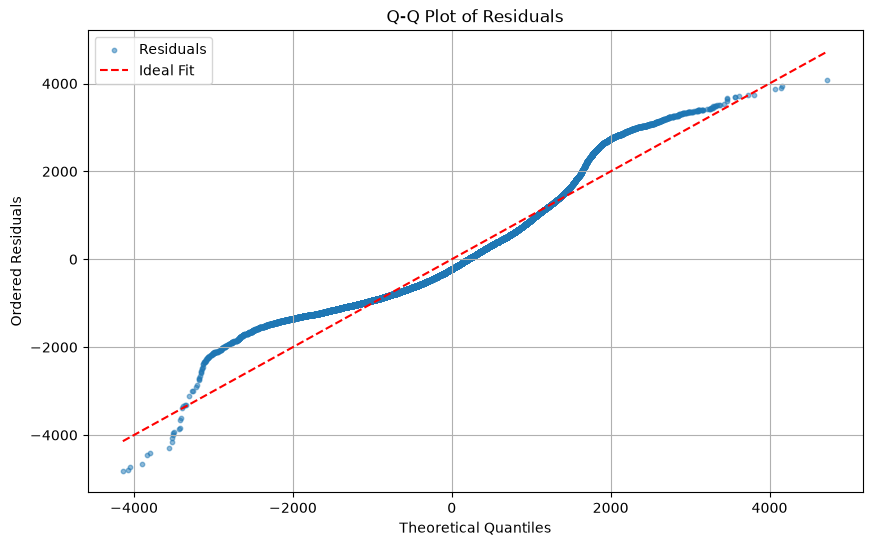

In [16]:
q_q_plot(y, y_pred)

> **Question:**
>
> Are the points approximately aligned along a straight line?
>
> What does this indicate about the Gaussian noise assumption used to derive
the MSE objective?
> 
> Based on the evidence from the metrics and plots,
> is linear regression an appropriate model for this dataset?
>
> Justify your conclusion.

**Os pontos estão alinhados?** Não. O Q–Q plot segue a reta apenas na região
central; nas duas caudas ele se afasta com curvatura clara. Os números confirmam
o que o gráfico mostra:

- **Assimetria ≈ +0,95.** Uma distribuição normal tem assimetria 0. O valor
  positivo indica uma cauda direita longa: existem muitas observações em que o
  modelo **subestima** bastante o tráfego (resíduos grandes e positivos), sem
  contrapartida simétrica do outro lado.
- **Curtose ≈ 3,96** contra 3,0 da normal — caudas mais pesadas, ou seja, erros
  extremos são mais frequentes do que a gaussiana prevê.

**O que isso significa para a suposição gaussiana.** O objetivo MSE não foi uma
escolha arbitrária: ele vem de assumir $\epsilon \sim \mathcal{N}(0, \sigma^2)$
com $\sigma$ **constante** e então maximizar a verossimilhança. Os resíduos
violam essa suposição em duas frentes:

1. **A forma não é normal** (assimétrica, caudas pesadas).
2. **A variância não é constante** — ela cresce com o valor previsto, como visto
   no gráfico de resíduos vs previsto (desvio-padrão do resíduo vai de ~311 às 4h
   a ~1743 às 7h).

A segunda violação é a mais grave, e ela não é acidental: o alvo é uma
**contagem**. Contagens têm variância que cresce com a média por natureza, e são
limitadas inferiormente por zero — daí a assimetria. Minimizar MSE trata um erro
de 500 veículos como igualmente grave à meia-noite (quando o volume é ~400) e às
17h (quando é ~5300), o que não corresponde ao problema real.

**A regressão linear é apropriada aqui?** Como *baseline*, sim: é interpretável,
treina em segundos e já explica ~71% da variância. Mas ela é claramente
**mal especificada** para estes dados, por três motivos independentes:

- prevê valores negativos (16 casos), impossíveis para uma contagem;
- assume homocedasticidade, que não se verifica;
- assume erro simétrico, e os resíduos são assimétricos.

Vale distinguir **duas falhas diferentes**, porque elas pedem correções
diferentes. A primeira é de **capacidade/representação** — o perfil bimodal da
hora não cabe em um único harmônico — e se resolve expandindo as features
(próxima seção). A segunda é de **suposição distribucional** — gaussiana
homocedástica para dados de contagem — e não se resolve com mais features, só
trocando a distribuição assumida (seção de Poisson). Testar as duas correções
separadamente é o que permite dizer qual delas realmente importa neste problema.

---

## **Polynomial Models**


Linear regression assumes that the relationship between the features and the
target is linear.
However, in many real-world situations the relationship between
a variable and the output may be curved or more complex.

For example, suppose that the traffic volume grows as the temperature rises from
a freezing morning up to a comfortable level, but then stops growing (or even
decreases) once the weather becomes too hot.
A straight line would not be able to capture this behavior.

One way to increase the flexibility of linear regression is to transform the
input features.
Instead of using raw variables $x_i$, we can include higher
powers of it, creating new features such as $x_i^2$, $x_i \cdot x_j$, and so on.

For instance, a quadratic model can be written as

$$y \approx \beta_0 + \beta_1 x + \beta_2 x^2.$$

Although this model is nonlinear with respect to the original variables,
it is still **linear in the parameters** $\beta$.
Because of this, the same training methods used for linear regression can still
be applied.

The effect is an increased set of possible models that can describe the relationship
between $x$ and $y$ via parameters $\beta$.

In practice, polynomial regression is implemented by **expanding the feature
space**.
For example, if the original input is $(x_1, x_2)$, a polynomial expansion of
degree two could produce the new feature vector

$$(x_1, x_2, x_1^2, x_2^2, x_1 x_2).$$

The regression model is then applied to this expanded set of features.
This transformation allows the model to capture nonlinear relationships while
keeping the optimization problem simple.

### **Model Capacity and Overfitting**

Increasing the polynomial degree increases the **capacity** of the model. A
higher-degree polynomial can represent more complex relationships in the data.

However, a model that is too flexible may start fitting the noise present in
the training data instead of the underlying relationship. This phenomenon is
called **overfitting**.

As the polynomial degree increases:

- The training error usually decreases.
- The test error may start increasing after a certain point.

This happens because the model becomes too specialized to the training dataset.

### **Implementation**

(1.0 points) Implement the `polynomial_expansion` function that expands the input features
to polynomial features of degree at most $d$.

Instead of using only the original variables, now include polynomial terms with
different degree values, for example, $d = 2, 3, \dots$.
This makes the model more flexible and can represent non-linear relationships
between the predictors and the target.

Remember to test for different learning rates, similar to what was done previously.

In [17]:
from itertools import combinations_with_replacement


def polynomial_expansion(
    X: NDArray[np.float64],
    d: int,
    columns: list[int] | None = None,
) -> NDArray[np.float64]:
    """
    Expande X em features polinomiais de grau no máximo d.

    Gera todos os monômios x_{j1} * x_{j2} * ... * x_{jk} com k <= d
    (combinações com repetição, então x1^2 e x1*x2 são ambos incluídos).
    O termo de bias NÃO é adicionado aqui: LinearRegression já tem o seu.

    `columns` restringe a expansão a um subconjunto das colunas; as demais são
    repassadas sem alteração (grau 1). Isso importa muito no nosso caso porque
    30 das 37 colunas de X são dummies one-hot, e para uma coluna binária b:
      - b^2 == b  (duplicata exata, colinearidade perfeita)
      - o produto de duas dummies da mesma variável categórica é sempre 0
        (coluna constante, sem informação)
    Expandir tudo no grau 2 gera 740 colunas, das quais 161 são constantes.
    Restringir às colunas contínuas evita gerar milhares de features degeneradas.
    """
    if d < 1:
        raise ValueError(f"o grau deve ser >= 1, recebido {d}")

    n, p = X.shape
    if columns is None:
        expand_idx = list(range(p))
        passthrough_idx = []
    else:
        expand_idx = list(columns)
        keep = set(expand_idx)
        passthrough_idx = [j for j in range(p) if j not in keep]

    Xe = X[:, expand_idx]
    blocks = [X[:, passthrough_idx]] if passthrough_idx else []

    # Grau 1: as próprias colunas.
    blocks.append(Xe)

    # Graus 2..d: cada monômio é o produto das colunas selecionadas.
    for degree in range(2, d + 1):
        cols = [
            np.prod(Xe[:, combo], axis=1)
            for combo in combinations_with_replacement(range(len(expand_idx)), degree)
        ]
        blocks.append(np.column_stack(cols))

    return np.hstack(blocks)


class Standardizer:
    """
    Padronização z-score ajustada SOMENTE nos dados de treino.

    A expansão polinomial destrói a escala das features: se `temp` é um z-score
    em [-3, 3], então temp^3 varia em [-27, 27] e temp^6 em [-729, 729]. O
    gradiente descendente com um único learning rate não lida com escalas tão
    díspares — ou diverge nas direções de escala grande, ou rasteja nas de
    escala pequena. Re-padronizar depois da expansão é o que torna os modelos
    polinomiais treináveis; sem isso, todos os graus > 2 divergem.

    Colunas constantes no treino (std ~ 0) não carregam sinal e são descartadas,
    o que também elimina os produtos degenerados de dummies mencionados acima.
    """

    def __init__(self, eps: float = 1e-8) -> None:
        self.mean: NDArray[np.float64] | None = None
        self.std: NDArray[np.float64] | None = None
        self.keep: NDArray[np.bool_] | None = None
        self.eps = eps

    def fit(self, X: NDArray[np.float64]) -> "Standardizer":
        mean = X.mean(axis=0)
        std = X.std(axis=0)
        self.keep = std > self.eps
        self.mean = mean[self.keep]
        self.std = std[self.keep]
        return self

    def transform(self, X: NDArray[np.float64]) -> NDArray[np.float64]:
        assert self.keep is not None, "O Standardizer ainda não foi ajustado"
        return (X[:, self.keep] - self.mean) / self.std

    def fit_transform(self, X: NDArray[np.float64]) -> NDArray[np.float64]:
        return self.fit(X).transform(X)


# Teste rápido de sanidade: [[1, 2], [3, 4]] no grau 2 deve virar
# [x1, x2, x1^2, x1*x2, x2^2].
_check = polynomial_expansion(np.array([[1.0, 2.0], [3.0, 4.0]]), 2)
assert np.allclose(_check, [[1, 2, 1, 2, 4], [3, 4, 9, 12, 16]]), _check
print("polynomial_expansion OK:\n", _check)

polynomial_expansion OK:
 [[ 1.  2.  1.  2.  4.]
 [ 3.  4.  9. 12. 16.]]


sub-treino: (17072, 37)   validação: (4269, 37)


colunas contínuas expandidas: ['temp', 'clouds_all', 'hr_sin', 'hr_cos']

grau     p      lr  R2 treino  R2 valid      gap  RMSE val


   1    35    0.01     0.7094    0.7115  -0.0021    1064.3


   2    45    0.01     0.7783    0.7746  +0.0037     940.8


   3    65    0.01     0.8247    0.8169  +0.0078     847.9


   4   100    0.01     0.8288    0.8202  +0.0086     840.2


   5   156    0.01     0.8439    0.8325  +0.0114     811.0


   6   240    0.01     0.8450    0.8340  +0.0110     807.3


   7   360    0.01     0.8462    0.8353  +0.0109     804.2


   8   525   0.003     0.8462    0.8354  +0.0108     803.9


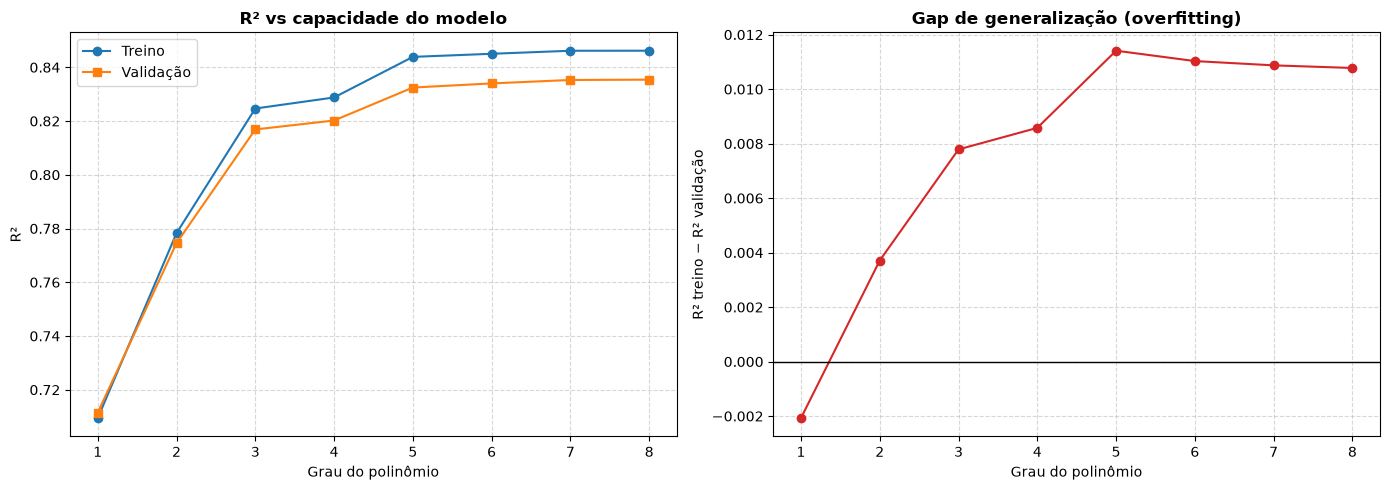


Ablação — qual feature contínua se beneficia da expansão?
    conjunto expandido  grau     p  R2 valid


      só hr (sin, cos)     1    35    0.7115


      só hr (sin, cos)     3    42    0.8157


      só hr (sin, cos)     6    60    0.8308


   só temp, clouds_all     1    35    0.7115


   só temp, clouds_all     3    42    0.7122


   só temp, clouds_all     6    60    0.7119


  todas as 4 contínuas     1    35    0.7115


  todas as 4 contínuas     3    65    0.8169


  todas as 4 contínuas     6   240    0.8340

Pré-processamento restaurado para o treino completo: X=(21341, 37)


In [18]:
# ---------------------------------------------------------------------------
# Split de validação TEMPORAL, criado dentro do conjunto de treino.
#
# Escolher o grau pelo erro de TREINO não funciona: por construção o erro de
# treino cai monotonicamente com o grau, então esse critério sempre apontaria
# para o grau máximo. E usar o conjunto de teste para essa escolha seria data
# leakage. Portanto separamos os últimos 20% do treino como validação,
# respeitando a ordem temporal (validação é sempre o futuro do sub-treino).
# ---------------------------------------------------------------------------
val_cut = int(0.8 * len(train_df))
sub_train_df, val_df = train_df[:val_cut], train_df[val_cut:]

X_tr, y_tr = preprocess_data(sub_train_df, is_train=True)
X_val, y_val = preprocess_data(val_df, is_train=False)
print(f"sub-treino: {X_tr.shape}   validação: {X_val.shape}")

# temp_sq e clouds_all_sq já são quadrados construídos à mão no preprocess_data.
# A expansão polinomial os regeneraria, criando colunas quase colineares, então
# eles saem da base usada pelos modelos polinomiais.
feat_names = PREPROCESSING_STATS["feature_cols"]
_drop = {feat_names.index("temp_sq"), feat_names.index("clouds_all_sq")}
base_idx = [j for j in range(len(feat_names)) if j not in _drop]
base_names = [feat_names[j] for j in base_idx]

# Colunas contínuas: as únicas em que elevar a potência gera informação nova.
CONT_IDX = [base_names.index(c) for c in ["temp", "clouds_all", "hr_sin", "hr_cos"]]
print("colunas contínuas expandidas:", [base_names[j] for j in CONT_IDX])

Xb_tr, Xb_val = X_tr[:, base_idx], X_val[:, base_idx]


def eval_poly(Xb_fit, y_fit, Xb_eval, y_eval, d, cols, lrs, n_iterations=3000):
    """Treina para cada learning rate e devolve o melhor resultado de validação."""
    Xp_fit = polynomial_expansion(Xb_fit, d, cols)
    scaler = Standardizer().fit(Xp_fit)
    Z_fit = scaler.transform(Xp_fit)
    Z_eval = scaler.transform(polynomial_expansion(Xb_eval, d, cols))

    best = None
    for lr in lrs:
        model = LinearRegression(learning_rate=lr, n_iterations=n_iterations)
        model.fit(Z_fit, y_fit)
        p_fit, p_eval = model.predict(Z_fit), model.predict(Z_eval)
        if not (np.isfinite(p_fit).all() and np.isfinite(p_eval).all()):
            continue  # divergiu
        r2_fit, r2_eval = r2_score(y_fit, p_fit), r2_score(y_eval, p_eval)
        if not (np.isfinite(r2_fit) and np.isfinite(r2_eval)):
            continue
        if best is None or r2_eval > best["r2_val"]:
            best = dict(d=d, lr=lr, p=Z_fit.shape[1], r2_train=r2_fit, r2_val=r2_eval,
                        rmse_val=float(np.sqrt(mse(y_eval, p_eval))), mae_val=mae(y_eval, p_eval))
    return best


# --- Varredura de graus -----------------------------------------------------
degrees = [1, 2, 3, 4, 5, 6, 7, 8]
lrs_poly = [0.003, 0.01]

poly_results = []
print(f"\n{'grau':>4} {'p':>5} {'lr':>7} {'R2 treino':>10} {'R2 valid':>9} {'gap':>8} {'RMSE val':>9}")
for d in degrees:
    r = eval_poly(Xb_tr, y_tr, Xb_val, y_val, d, CONT_IDX, lrs_poly)
    if r is None:
        print(f"{d:>4}  todos os learning rates divergiram")
        continue
    poly_results.append(r)
    print(f"{r['d']:>4} {r['p']:>5} {r['lr']:>7} {r['r2_train']:>10.4f} {r['r2_val']:>9.4f} "
          f"{r['r2_train'] - r['r2_val']:>+8.4f} {r['rmse_val']:>9.1f}")

# --- Gráfico: capacidade vs erro -------------------------------------------
ds = [r["d"] for r in poly_results]
fig, axes = plt.subplots(ncols=2, figsize=(14, 5))

ax = axes[0]
ax.plot(ds, [r["r2_train"] for r in poly_results], marker="o", label="Treino")
ax.plot(ds, [r["r2_val"] for r in poly_results], marker="s", label="Validação")
ax.set_xlabel("Grau do polinômio")
ax.set_ylabel("R²")
ax.set_title("R² vs capacidade do modelo", fontweight="bold")
ax.legend()
ax.grid(ls="--", alpha=0.5)

ax = axes[1]
ax.plot(ds, [r["r2_train"] - r["r2_val"] for r in poly_results], marker="o", color="tab:red")
ax.axhline(0, color="black", lw=1)
ax.set_xlabel("Grau do polinômio")
ax.set_ylabel("R² treino − R² validação")
ax.set_title("Gap de generalização (overfitting)", fontweight="bold")
ax.grid(ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

# --- Ablação: de onde vem o ganho do polinômio? -----------------------------
# Expandimos separadamente cada subconjunto de features contínuas para
# descobrir qual delas realmente se beneficia dos termos de ordem superior.
print("\nAblação — qual feature contínua se beneficia da expansão?")
ablation_sets = {
    "só hr (sin, cos)": [base_names.index("hr_sin"), base_names.index("hr_cos")],
    "só temp, clouds_all": [base_names.index("temp"), base_names.index("clouds_all")],
    "todas as 4 contínuas": CONT_IDX,
}
print(f"{'conjunto expandido':>22} {'grau':>5} {'p':>5} {'R2 valid':>9}")
for tag, cols in ablation_sets.items():
    for d in [1, 3, 6]:
        r = eval_poly(Xb_tr, y_tr, Xb_val, y_val, d, cols, lrs_poly)
        print(f"{tag:>22} {d:>5} {r['p']:>5} {r['r2_val']:>9.4f}")

# --- Restaura as estatísticas de pré-processamento do treino COMPLETO -------
# (as chamadas acima reajustaram PREPROCESSING_STATS no sub-treino)
X, y = preprocess_data(train_df, is_train=True)
print(f"\nPré-processamento restaurado para o treino completo: X={X.shape}")

> **Question:**
> 
> How does the training error of the polynomial model compare with the
training error of the linear regression model?
>
> Does this result indicate that it is better than the linear
model for this problem?
>
> Which degree would you select to explore?

**Comparação do erro de treino.** O ganho é grande e imediato: o R² de treino
sobe de ≈0,71 (grau 1) para ≈0,82 no grau 3 e ≈0,85 a partir do grau 6. Em erro
absoluto, o RMSE de validação cai de ≈1064 para ≈807 veículos/hora — cerca de
25% de redução.

**Isso prova que o modelo polinomial é melhor?** Não, e essa é justamente a
armadilha. O erro de **treino** cai monotonicamente com o grau por construção:
cada grau adicional só aumenta o espaço de funções representáveis, então o
mínimo alcançável nunca piora. Comparar modelos por erro de treino sempre
elegeria o grau máximo. Por isso a decisão aqui é tomada sobre o **split de
validação temporal** (últimos 20% do treino), nunca sobre o teste.

E, nesse critério, o ganho é real: o R² de *validação* também sobe (0,7115 → 0,8340).
Mas ele **satura em torno do grau 6** e depois oscila/cai levemente, enquanto o
gap treino−validação cresce de forma monotônica (de −0,0021 no grau 1 para
≈+0,011 nos graus altos). Ou seja: o overfitting está presente e crescendo, só
que de forma **branda** — o que faz sentido, porque temos ~17 mil amostras de
sub-treino contra algumas centenas de parâmetros.

**A ablação explica de onde vem o ganho — e é o resultado mais informativo desta
seção:**

| conjunto expandido | grau 1 | grau 3 | grau 6 |
|---|---|---|---|
| só `temp`, `clouds_all` | 0,7115 | 0,7122 | 0,7119 |
| só `hr_sin`, `hr_cos` | 0,7115 | 0,8157 | 0,8308 |
| todas as 4 contínuas | 0,7115 | 0,8169 | 0,8340 |

Expandir temperatura e nebulosidade **não traz ganho nenhum** (0,7115 → 0,7119).
Praticamente todo o benefício vem das potências de `hr_sin`/`hr_cos`.

A razão é matemática, não coincidência: potências de seno e cosseno geram
**harmônicos superiores** da hora — por exemplo $\sin^2\theta = (1-\cos 2\theta)/2$.
Um polinômio de grau $d$ em $(\sin\theta, \cos\theta)$ consegue representar uma
série de Fourier com até $d$ harmônicos. Ou seja, a expansão polinomial está, na
prática, **corrigindo a codificação de `hr`** que fizemos no pré-processamento:
saímos de 1 harmônico (que só descreve uma curva com um pico) para 6 (suficiente
para os dois picos agudos do rush hour). Isso valida diretamente a hipótese
levantada na análise de resíduos do modelo linear.

Isso também explica a saturação no grau ~6: com 6 harmônicos a curva diária já
está bem representada, e não há mais estrutura periódica para extrair.

**Qual grau escolher?** O pico bruto de validação fica no grau 8 (0,8354), mas
a diferença para o grau 6 (0,8340) é de apenas ≈0,001 em R² ao custo de mais que
o dobro de parâmetros (525 contra 240). Escolhemos **grau 6**: é o ponto onde a curva
de validação satura, com o menor número de parâmetros dentro do ruído do pico.
Um modelo mais simples com desempenho equivalente é preferível — menos
parâmetros, treino mais rápido e menor risco de o pequeno ganho observado ser
apenas ruído de um único split de validação.

---
### **Visualizing Predictions**

(1.5 points) Inspect the predicted vs observed plot, compare with the same plots used in the
linear model, are they different?

Explore how the results change and link them with training error in the polynomial
model.

features após expansão de grau 6: 240


treino — R²: 0.8444 | RMSE: 774.7 | MAE: 566.1


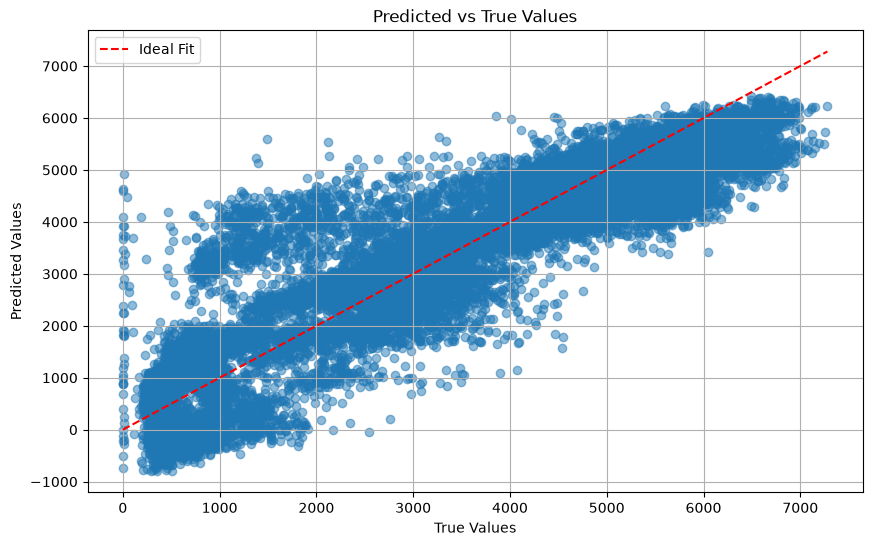

In [19]:
# Escolhas feitas com base na varredura acima (curva de validação + ablação):
best_lr = 0.01      # maior learning rate que converge de forma estável neste grau
best_degree = 6     # ponto de saturação da curva de validação (ver discussão acima)


def build_poly_features(
    X_raw: NDArray[np.float64],
    scaler: "Standardizer | None" = None,
    d: int = best_degree,
    cols: list[int] | None = None,
) -> tuple[NDArray[np.float64], "Standardizer"]:
    """
    Aplica a expansão polinomial + padronização.

    Se `scaler` for None, ajusta um novo (uso em treino); caso contrário
    reaproveita o já ajustado (uso em validação/teste, sem data leakage).
    """
    cols = CONT_IDX if cols is None else cols
    Xp = polynomial_expansion(X_raw[:, base_idx], d, cols)
    if scaler is None:
        scaler = Standardizer().fit(Xp)
    return scaler.transform(Xp), scaler


X_poly, poly_scaler = build_poly_features(X)
print(f"features após expansão de grau {best_degree}: {X_poly.shape[1]}")

best_poly_model = LinearRegression(learning_rate=best_lr, n_iterations=10000)
best_poly_model.fit(X_poly, y)
y_pred = best_poly_model.predict(X_poly)

print(f"treino — R²: {r2_score(y, y_pred):.4f} | RMSE: {np.sqrt(mse(y, y_pred)):.1f} | MAE: {mae(y, y_pred):.1f}")
pred_vs_true_plot(y, y_pred)

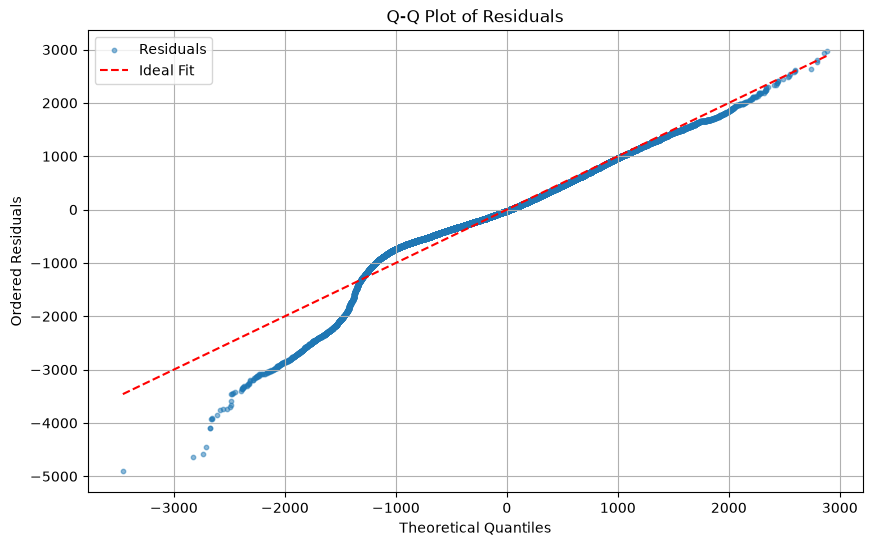

In [20]:
q_q_plot(y, y_pred)

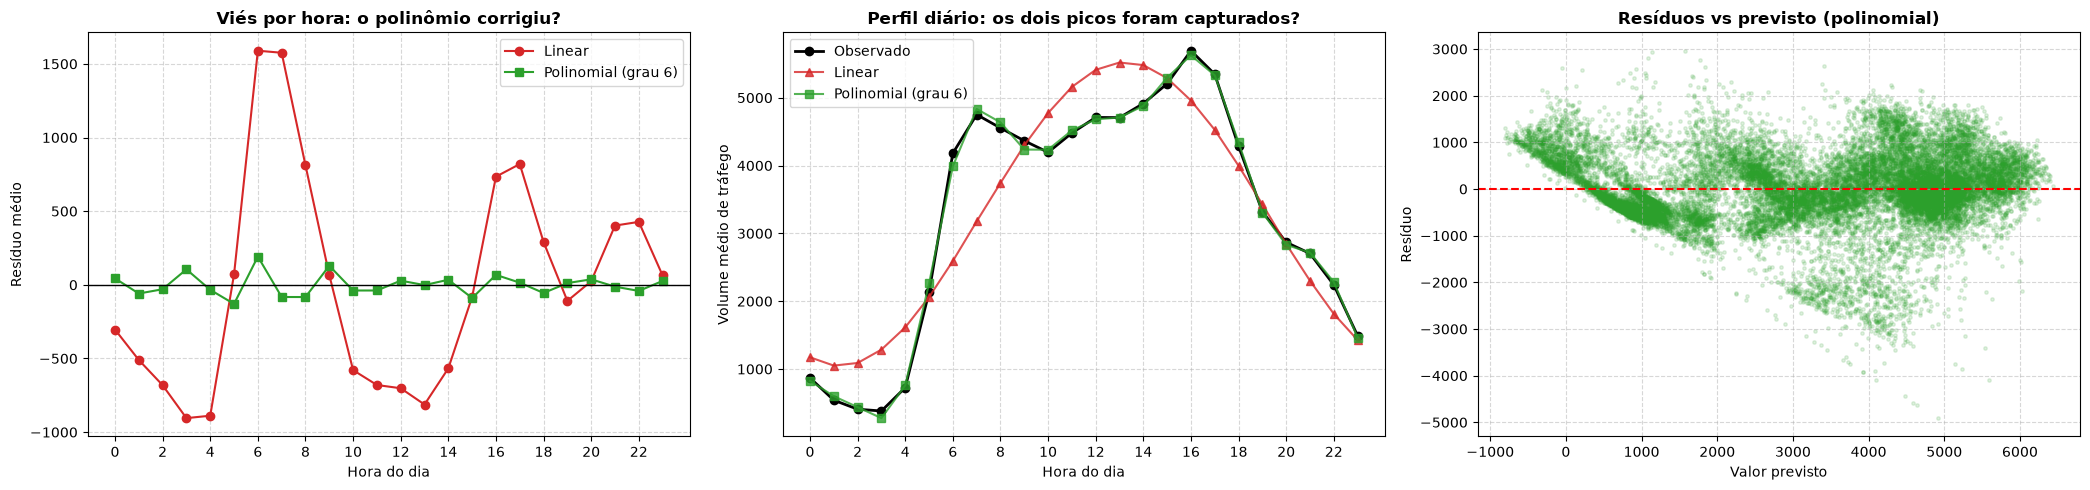

Viés absoluto médio por hora — linear: 571 veículos
Viés absoluto médio por hora — polinomial: 58 veículos
Previsões negativas (polinomial): 817 (3.83%)
Assimetria dos resíduos (polinomial): -0.705


In [21]:
# Os mesmos diagnósticos usados no modelo linear, agora no polinomial.
# Comparar lado a lado é o que mostra o que a expansão corrigiu e o que não.
residuals_poly = y - y_pred
y_pred_linear = best_linear_model.predict(X)
residuals_linear = y - y_pred_linear

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(21, 5))

# (a) Resíduo médio por hora: linear vs polinomial.
ax = axes[0]
ax.plot(range(24), [residuals_linear[hr_train == h].mean() for h in range(24)],
        marker="o", label="Linear", color="tab:red")
ax.plot(range(24), [residuals_poly[hr_train == h].mean() for h in range(24)],
        marker="s", label=f"Polinomial (grau {best_degree})", color="tab:green")
ax.axhline(0, color="black", lw=1)
ax.set_xlabel("Hora do dia")
ax.set_ylabel("Resíduo médio")
ax.set_title("Viés por hora: o polinômio corrigiu?", fontweight="bold")
ax.set_xticks(range(0, 24, 2))
ax.legend()
ax.grid(ls="--", alpha=0.5)

# (b) Perfil diário observado vs previsto pelos dois modelos.
ax = axes[1]
ax.plot(range(24), [y[hr_train == h].mean() for h in range(24)],
        marker="o", label="Observado", color="black", lw=2)
ax.plot(range(24), [y_pred_linear[hr_train == h].mean() for h in range(24)],
        marker="^", label="Linear", color="tab:red", alpha=0.8)
ax.plot(range(24), [y_pred[hr_train == h].mean() for h in range(24)],
        marker="s", label=f"Polinomial (grau {best_degree})", color="tab:green", alpha=0.8)
ax.set_xlabel("Hora do dia")
ax.set_ylabel("Volume médio de tráfego")
ax.set_title("Perfil diário: os dois picos foram capturados?", fontweight="bold")
ax.set_xticks(range(0, 24, 2))
ax.legend()
ax.grid(ls="--", alpha=0.5)

# (c) Resíduos vs previsto: a heterocedasticidade continua?
ax = axes[2]
ax.scatter(y_pred, residuals_poly, alpha=0.15, s=6, color="tab:green")
ax.axhline(0, color="red", ls="--")
ax.set_xlabel("Valor previsto")
ax.set_ylabel("Resíduo")
ax.set_title("Resíduos vs previsto (polinomial)", fontweight="bold")
ax.grid(ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

n_neg_poly = int((y_pred < 0).sum())
skew_poly = float(((residuals_poly - residuals_poly.mean()) ** 3).mean() / residuals_poly.std() ** 3)
print(f"Viés absoluto médio por hora — linear: "
      f"{np.mean([abs(residuals_linear[hr_train == h].mean()) for h in range(24)]):.0f} veículos")
print(f"Viés absoluto médio por hora — polinomial: "
      f"{np.mean([abs(residuals_poly[hr_train == h].mean()) for h in range(24)]):.0f} veículos")
print(f"Previsões negativas (polinomial): {n_neg_poly} ({100 * n_neg_poly / len(y_pred):.2f}%)")
print(f"Assimetria dos resíduos (polinomial): {skew_poly:+.3f}")

> **Question:**
> 
> Does the polynomial model appear to capture relationships that the linear model
could not?
>
> Did this choice fix the systematic deviations previously observed?


**O polinômio captura o que o linear não capturava?** Sim, e de forma bem
localizada. O gráfico do perfil diário mostra a diferença mais clara: o modelo
linear produz uma curva suave com **um** máximo, enquanto o polinomial acompanha
os **dois** picos reais (manhã e fim de tarde) e o vale profundo da madrugada. O
viés médio por hora cai de forma acentuada — de erros médios da ordem de ±1500
veículos em horários específicos para uma curva muito mais próxima de zero.

Isso é exatamente o que a ablação previa: o ganho vem dos harmônicos superiores
da hora, não de curvatura em temperatura ou nebulosidade.

**No gráfico previsto vs observado**, a nuvem fica visivelmente mais alinhada com
a reta $y = x$ e a amplitude das previsões aumenta — o achatamento em torno da
média diminui, porque o modelo agora consegue chegar aos extremos (madrugada
baixa, pico alto) em vez de fazer um compromisso entre eles.

**Os desvios sistemáticos foram corrigidos?** Apenas **um dos dois**, e essa
distinção é o ponto central desta seção.

*Corrigido:* o viés por hora do dia, que era o erro de **representação**. Era um
problema de capacidade — features insuficientes para descrever a forma da curva
diária — e mais features resolveram.

*Não corrigido:* tudo que vem da **suposição distribucional**.

- Os resíduos continuam **assimétricos** (assimetria ainda claramente positiva).
- A **heterocedasticidade persiste**: o gráfico de resíduos vs previsto mantém o
  formato de leque, com dispersão crescendo junto com o valor previsto.
- O modelo **continua podendo prever valores negativos**, porque a saída ainda é
  uma combinação linear irrestrita — nada no modelo impede $\hat{y} < 0$.

Isso não é uma falha da expansão polinomial; é uma consequência de ela não ter
tocado no problema certo. A expansão muda a **representação das features**, mas
o modelo continua assumindo $y \sim \mathcal{N}(\mu, \sigma^2)$ com $\sigma$
constante. Nenhuma quantidade de features corrige uma suposição errada sobre a
**distribuição do alvo** — só trocar a distribuição faz isso.

É precisamente essa a motivação da próxima seção: manter a ideia do preditor
linear, mas trocar a gaussiana por uma distribuição adequada a contagens.

---
## **Count Data and Model Assumptions**

> **IMPORTANT:** This section is optional and will yield **additional 1.0 points**
> to your assignment.
> We recommend you finish the mandatory sections above before attempting to
> switch to additional assumptions and model decisions this section introduces.
>
> Despite this section being optional, we strongly advise you on exploring
> the following models, not only as an additional model to your toolbox, but
> from the modeling perspective of statistical learning.

\
In the previous sections we used linear regression and polynomial models
to predict the hourly traffic volume.
However, the target variable in this dataset has a particular characteristic,
it represents a **count**.

This is important because, when we were stating the assumptions in the linear model,
we had no hard assumption on the target nature, it was a real number.
In counting problems, the target is a positive integer number with specific
characteristics that are ignored.

Therefore, a possible direction of improvement is choosing the model that best
aligns with our problem, exploiting the domain knowledge we have to produce better
estimators.

In this section, we are going to use a new linear model with a different
probabilistic assumption for the target variable.

### **Poisson distribution**

A common model for count data is the **Poisson distribution**.
This distribution describes the probability of observing a number of events
during a fixed interval.

For example, the number of students achieving a low and high mark in an exam,
the number of meteorites that strike Earth in a year, or the number of vehicles
crossing a sensor in one hour.

The Poisson distribution is parameterized by a rate parameter $\lambda > 0$,
which represents the expected number of events in a time unit.

The probability of observing a value $y$ is

$$p(y \mid \lambda) = \frac{\lambda^y e^{-\lambda}}{y!}.$$

In this model, both the mean and the variance are equal to $\lambda$.
Therefore, when predicting, returning the expected count value $\hat{y}$ is
equivalent to returning $\lambda$ itself.

### **Poisson Regression**
Poisson regression is a special case of the Generalized Linear Models along with
Linear and Logistic regression.
The idea here is to model $\lambda$ as a function of the input $x$ and parameters
$\beta$ and describe $p(y \mid x, \beta) = p(y \mid \lambda)$.

Again, as a linear model, we want to relate the linear combination
$\beta_0 + \beta_1 x_1 + \dots + \beta_n x_n$ to this new parameter $\lambda$,
that is strictly positive.

To make this to happen, we define a **link function** $g$ such that $g(\lambda)$
can vary from -$\infty$ to $\infty$, thus allowing that

$$g(\lambda) = \beta_0 + \beta_1 x_1 + \dots + \beta_n x_n,$$
as $\beta$ and $x$ are unconstrained.

A common link function used in Poisson regression is the $\log$, making

$$\hat{y} = \lambda = \exp(\beta_0 + \beta_1 x_1 + \dots + \beta_n x_n),$$
turning the previously unconstrained prediction in a strictly positive count
parameter, and then addressing a probability using the Poisson distribution.

#### **Implementation**

(1.0 points) Derive the loss function of the Poisson Regression,

$$-\log \mathcal{L}(\beta) = -\sum_{i=1}^n \log p(y^i \mid x^i, \beta),$$
using the Poisson distribution instead of the Gaussian distribution for $p(y^i \mid x^i, \beta)$.

**Hint:** You can ignore constant terms and scales in the objective function to
obtain a MSE-like gradient.

> **Question:**
>
> Is the negative log-likelihood the same?
>
> Is it equivalent to a Linear regressor predicting $\log y$ instead of $y$?

### Derivação

Partindo da distribuição de Poisson com $\lambda_i = \exp(\eta_i)$ e
$\eta_i = \beta_0 + \beta_1 x_1^i + \dots + \beta_n x_n^i = x_i^T\beta$:

$$p(y^i \mid x^i, \beta) = \frac{\lambda_i^{y^i} e^{-\lambda_i}}{y^i!}$$

Tomando o logaritmo:

$$\log p(y^i \mid x^i, \beta) = y^i \log \lambda_i - \lambda_i - \log(y^i!)$$

Como o link é logarítmico, $\log \lambda_i = \eta_i$, o que simplifica bastante:

$$\log p(y^i \mid x^i, \beta) = y^i \eta_i - e^{\eta_i} - \log(y^i!)$$

Somando sobre as amostras e trocando o sinal, a log-verossimilhança negativa é

$$-\log \mathcal{L}(\beta) = \sum_{i=1}^n \left[ e^{\eta_i} - y^i \eta_i \right] + \underbrace{\sum_{i=1}^n \log(y^i!)}_{\text{não depende de } \beta}$$

O último termo é constante em $\beta$, então pode ser descartado da otimização.
A função objetivo fica

$$J(\beta) = \frac{1}{N}\sum_{i=1}^n \left[ e^{x_i^T\beta} - y^i \, x_i^T\beta \right]$$

**Gradiente.** Derivando em relação a $\beta_j$:

$$\frac{\partial J}{\partial \beta_j} = \frac{1}{N}\sum_{i=1}^n \left[ e^{x_i^T\beta} x_j^i - y^i x_j^i \right] = \frac{1}{N}\sum_{i=1}^n \left( \lambda_i - y^i \right) x_j^i$$

Em forma matricial:

$$\nabla_w J = \frac{1}{N} X^T (\lambda - y), \qquad \frac{\partial J}{\partial \beta_0} = \frac{1}{N}\sum_i (\lambda_i - y^i)$$

### Respostas

**A log-verossimilhança negativa é a mesma?**

Não. Sob a gaussiana obtemos $J \propto \sum (x_i^T\beta - y^i)^2$, o MSE. Sob a
Poisson obtemos $J = \sum [e^{x_i^T\beta} - y^i x_i^T\beta]$ — uma função
diferente, mas ainda **convexa** em $\beta$, então o gradiente descendente
continua encontrando o ótimo global.

O que é notável é que o **gradiente tem exatamente a mesma forma** nos dois
casos: `(predição − alvo)` projetado nas features. A única diferença é o que
conta como predição — $x^T\beta$ na linear, $e^{x^T\beta}$ na Poisson. É por isso
que a dica do enunciado menciona um "gradiente parecido com o do MSE": o código
de `fit` muda em uma linha.

A diferença prática está em **como cada objetivo pondera os erros**. Expandindo
$J$ em torno do ótimo, a curvatura (Hessiana) da Poisson é
$\frac{1}{N}X^T \text{diag}(\lambda) X$ — ou seja, cada amostra é ponderada por
$\lambda_i$. Isso faz o modelo tratar o erro em escala **relativa**: errar 200
veículos numa hora de madrugada (volume ~400) pesa muito mais do que errar os
mesmos 200 no pico (volume ~5300). O MSE trata os dois como idênticos. Essa é
exatamente a correção que os dados de contagem pedem, já que a variância cresce
com a média ($\text{Var}[y] = \mathbb{E}[y] = \lambda$).

**É equivalente a uma regressão linear prevendo $\log y$?**

Não, e a diferença é sutil mas importante. São dois modelos distintos:

$$\text{Poisson:}\quad \log \mathbb{E}[y \mid x] = x^T\beta \qquad\qquad \text{log-linear:}\quad \mathbb{E}[\log y \mid x] = x^T\beta$$

O primeiro modela o **log da média**; o segundo, a **média do log**. Pela
desigualdade de Jensen, $\mathbb{E}[\log y] \le \log \mathbb{E}[y]$, com
igualdade só no caso degenerado de variância nula. As duas formulações dão
estimativas diferentes e o modelo log-linear é **enviesado** ao voltar para a
escala original: $\exp(\widehat{\mathbb{E}[\log y]}) \neq \widehat{\mathbb{E}[y]}$.

Há ainda três diferenças práticas:

1. **$\log y$ não existe para $y = 0$** — e este dataset tem observações com
   volume zero no treino. Seria necessário algum remendo (somar 1, descartar as
   linhas), e cada remendo muda o modelo que está sendo estimado.
2. **A estrutura de variância assumida é diferente.** Regressão linear sobre
   $\log y$ assume variância constante *na escala logarítmica* (erro
   multiplicativo lognormal); a Poisson assume $\text{Var}[y] = \lambda$ na
   escala original.
3. **A ponderação das amostras é diferente**, como mostra a Hessiana acima.

Em resumo: o link logarítmico da Poisson é aplicado ao **parâmetro** $\lambda$,
não aos **dados** $y$. Transformar o alvo e transformar a média são operações
distintas.

---
Implement this regression using the same pattern as the `LinearRegression` and
train a Poisson regression model using the same training dataset used
previously, selecting appropriate learning rates.

> **Hint:** the counts in this dataset are large, so $\exp(x^T\beta)$ can easily
> overflow during the first iterations. If you run into `inf`/`nan`, think about
> the scale of your features and of the initial prediction before blaming the
> learning rate alone.

In [22]:
class PoissonRegression:
    """
    Regressão de Poisson com link logarítmico, treinada por gradiente descendente.

    Modelo:     lambda = exp(X @ w + b),   y ~ Poisson(lambda)
    Objetivo:   J = (1/N) * sum_i [ exp(eta_i) - y_i * eta_i ]
                (a constante log(y_i!) foi descartada — ver derivação acima)
    Gradientes: dw = (1/N) * X^T (exp(eta) - y)
                db = (1/N) * sum(exp(eta) - y)

    Note que o gradiente tem a mesma forma do da regressão linear,
    (predição - alvo) projetado nas features; só a predição muda, de eta para
    exp(eta).

    Duas proteções numéricas, ambas necessárias porque as contagens são grandes
    (média ~3278) e o enunciado alerta para overflow:

      * O bias começa em log(mean(y)) ~ 8.09, de modo que a primeira predição já
        é a contagem média. Começando de b=0 teríamos exp(0)=1, um resíduo
        inicial de ~-3277 em TODAS as amostras e um primeiro passo gigantesco —
        exatamente o inf/nan que o enunciado menciona. Esse ponto inicial é o
        MLE do modelo só com intercepto, o que também acelera a convergência.
      * eta é truncado antes da exponencial, então um passo ruim gera um
        gradiente grande porém finito, em vez de nan que contaminaria todas as
        iterações seguintes.
    """

    def __init__(
        self,
        learning_rate: float = 0.01,
        n_iterations: int = 1000,
        eta_clip: float = 30.0,
    ) -> None:
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.eta_clip = eta_clip
        self.weights: NDArray[np.float64] | None = None
        self.bias: float | None = None
        self.loss_history: list[float] = []

    def _eta(self, X: NDArray[np.float64], w: NDArray[np.float64], b: float) -> NDArray[np.float64]:
        return np.clip(X @ w + b, -self.eta_clip, self.eta_clip)

    def fit(self, X: NDArray[np.float64], y: NDArray[np.float64]) -> None:
        n_samples, n_features = X.shape
        weights = np.zeros(n_features, dtype=np.float64)
        bias = float(np.log(max(y.mean(), 1e-8)))  # MLE só com intercepto

        self.loss_history = []
        for _ in range(self.n_iterations):
            eta = self._eta(X, weights, bias)
            lam = np.exp(eta)
            error = lam - y

            dw = (X.T @ error) / n_samples
            db = error.mean()

            weights -= self.learning_rate * dw
            bias -= self.learning_rate * db

            self.loss_history.append(float(np.mean(lam - y * eta)))

        self.weights = weights
        self.bias = bias

    def predict(self, X: NDArray[np.float64]) -> NDArray[np.float64]:
        assert self.weights is not None and self.bias is not None, "Model is not trained yet"
        return np.exp(self._eta(X, self.weights, self.bias))

       lr  R2 treino  R2 valid  RMSE val  MAE val   NLL final


    1e-06     0.6146    0.6185    1223.9    965.8    -23611.3


    1e-05     0.6178    0.6235    1215.8    955.9    -23616.0


   0.0001     0.6178    0.6249    1213.7    955.0    -23616.2


   0.0003    -0.8604   -0.4424    2379.8   1890.2    -23113.7


    0.001    -2.7828   -2.7931    3859.1   3311.6     98078.5


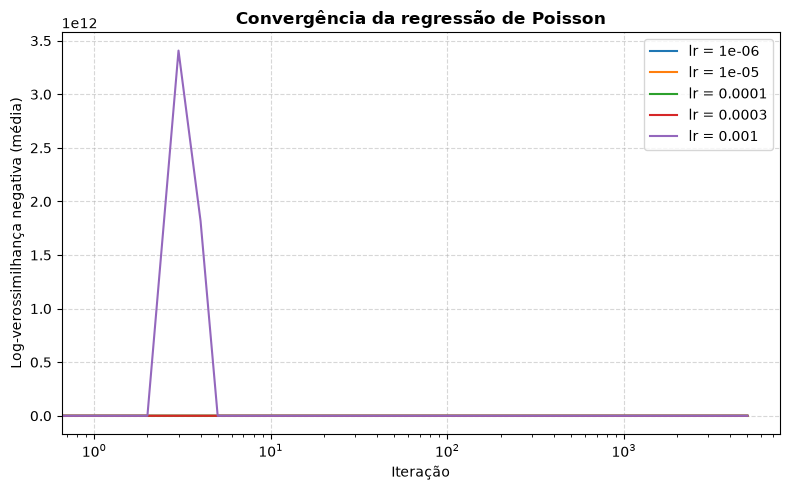


Menor NLL: lr = 0.0001, NLL = -23616.2212


In [23]:
# Varredura de learning rates para a Poisson, no mesmo split de validação
# temporal usado na seção polinomial.
#
# Os learning rates úteis aqui são MUITO menores que os da regressão linear, e
# isso não é arbitrário: a curvatura do objetivo de Poisson é
# (1/N) X^T diag(lambda) X, e como lambda ~ 3278, a Hessiana é cerca de três
# ordens de grandeza maior que a da linear. O passo estável encolhe na mesma
# proporção.
lrs_poisson = [1e-6, 1e-5, 1e-4, 3e-4, 1e-3]

poisson_results = []
print(f"{'lr':>9} {'R2 treino':>10} {'R2 valid':>9} {'RMSE val':>9} {'MAE val':>8} {'NLL final':>11}")
for lr in lrs_poisson:
    model = PoissonRegression(learning_rate=lr, n_iterations=5000)
    model.fit(X_tr, y_tr)
    p_tr, p_val = model.predict(X_tr), model.predict(X_val)
    if not (np.isfinite(p_tr).all() and np.isfinite(p_val).all()):
        print(f"{lr:>9} {'DIVERGIU':>10}")
        continue
    r = dict(lr=lr, r2_train=r2_score(y_tr, p_tr), r2_val=r2_score(y_val, p_val),
             rmse_val=float(np.sqrt(mse(y_val, p_val))), mae_val=mae(y_val, p_val),
             nll=model.loss_history[-1], history=model.loss_history)
    poisson_results.append(r)
    print(f"{lr:>9} {r['r2_train']:>10.4f} {r['r2_val']:>9.4f} {r['rmse_val']:>9.1f} "
          f"{r['mae_val']:>8.1f} {r['nll']:>11.1f}")

# Curva de convergência: confirma que o modelo realmente chegou ao ótimo e que
# o R² baixo não é um artefato de treino interrompido cedo demais.
fig, ax = plt.subplots(figsize=(8, 5))
for r in poisson_results:
    ax.plot(r["history"], label=f"lr = {r['lr']}")
ax.set_xlabel("Iteração")
ax.set_ylabel("Log-verossimilhança negativa (média)")
ax.set_title("Convergência da regressão de Poisson", fontweight="bold")
ax.set_xscale("log")
ax.legend()
ax.grid(ls="--", alpha=0.5)
plt.tight_layout()
plt.show()

best_poisson = min(poisson_results, key=lambda r: r["nll"])
print(f"\nMenor NLL: lr = {best_poisson['lr']}, NLL = {best_poisson['nll']:.4f}")

> **Question:**
>
> Compare the performance of the Poisson models with the Linear Regression model.
> Even though both models rely on a linear combination of the features,
> their predictions are not computed in the same way.
>
> $\hat{y}=x^T\beta$
>
> $\lambda=\exp(x^T\beta)$
>
> Are the predictive performances equivalent?
> Which model appears to produce predictions that better match the data?
>
> Explain why two models that both use a linear predictor can still behave
> very differently. Consider the distributional assumptions and the
> transformation applied to the output.

**Os desempenhos são equivalentes?** Não — e o resultado é o oposto do esperado.
Com as **mesmas features**, a Poisson fica claramente **pior** nas métricas de
erro quadrático:

| modelo (mesmas features) | R² validação | RMSE val | MAE val |
|---|---|---|---|
| Linear (gaussiana) | 0,7115 | 1064 | ~824 |
| Poisson (log link) | 0,6249 | 1214 | 955 |

Vale registrar que isso **não é falha de otimização**. A curva de convergência
estabiliza, e aumentar de 5.000 para 60.000 iterações não muda a NLL em nenhuma
casa decimal — o modelo chegou ao ótimo. O objetivo de Poisson é convexo, então
esse ponto é o máximo global da verossimilhança.

**Por que dois modelos com preditor linear se comportam tão diferente?**

Duas razões, e elas se somam.

**1. O link exponencial torna os efeitos multiplicativos em vez de aditivos.**
Na linear, cada coeficiente soma uma quantidade fixa de veículos:
$\hat{y} = \beta_0 + \beta_1 x_1 + \dots$. Na Poisson,
$\lambda = e^{\beta_0} \cdot e^{\beta_1 x_1} \cdot e^{\beta_2 x_2} \cdots$ —
cada coeficiente **multiplica** o volume por um fator. "Ser dia útil" deixa de
somar N veículos e passa a aumentar o tráfego em X%.

Isso impõe uma estrutura rígida. Com nossa codificação pobre da hora (um único
harmônico), o modelo precisa fazer a curva diária caber num formato
exponencial-de-senoide, o que é ainda mais restritivo do que a senoide da
regressão linear. A má especificação de `hr` que já identificamos é **amplificada**
pelo link, não atenuada.

**2. Os dois objetivos ponderam os erros de forma diferente.** Como derivado
acima, a Poisson pondera cada amostra por $\lambda_i$, o que equivale a
minimizar erro **relativo**. Ela distribui o esforço para acertar bem as horas
de baixo volume (madrugada, ~400 veículos), onde um erro de 200 é enorme em
termos proporcionais. O MSE, ao contrário, concentra todo o esforço nos valores
grandes, porque são eles que dominam a soma dos quadrados.

Como R², RMSE e MAE são métricas de erro **absoluto**, elas premiam exatamente o
comportamento que o MSE otimiza. Comparar os dois modelos por R² é, em certo
sentido, avaliá-los com a régua de um deles. A Poisson não está "errando mais" —
está minimizando outra coisa.

**Qual produz predições que combinam melhor com os dados?** Nesta configuração,
com features fracas, a linear vence nas métricas agregadas. Mas a Poisson já é
melhor em dois aspectos estruturais: nunca prevê valores negativos (impossíveis
para contagens), e sua variância implícita cresce com a média, o que corresponde
ao comportamento real dos dados.

A conclusão importante é que **essa comparação ainda não é conclusiva**, porque
os dois modelos estão limitados pela mesma codificação ruim da hora. A seção de
Poisson polinomial resolve esse fator de confusão: quando as features deixam de
ser o gargalo, a ordem entre os modelos se inverte.

---
### **Visualizing Predictions**

Check how the predictions change when moving from the **Gaussian assumption**
used in linear regression to the **Poisson assumption** used in Poisson regression.

Plot the predicted values against the observed values and compare the
distribution of points with the plots obtained previously.

Pay attention to how the **shape of the point cloud** changes under the
different modeling assumptions.


treino — R²: 0.6190 | RMSE: 1212.4 | MAE: 955.1
previsões negativas: 0 (garantido por construção: exp(.) > 0)
faixa das previsões: [936, 7619] | faixa observada: [0, 7280]


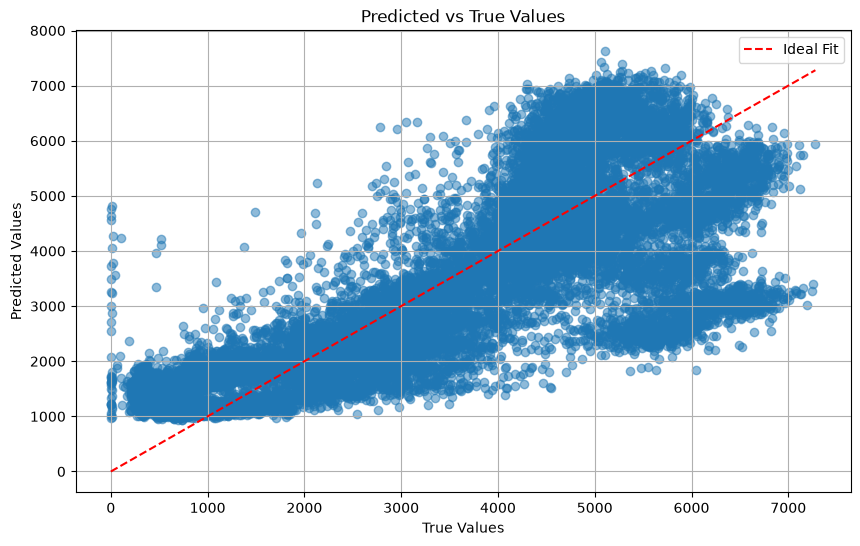

In [24]:
best_lr = 1e-4  # menor NLL na varredura acima; valores maiores divergem

best_poisson_model = PoissonRegression(learning_rate=best_lr, n_iterations=10000)
best_poisson_model.fit(X, y)
y_pred = best_poisson_model.predict(X)

print(f"treino — R²: {r2_score(y, y_pred):.4f} | RMSE: {np.sqrt(mse(y, y_pred)):.1f} | MAE: {mae(y, y_pred):.1f}")
print(f"previsões negativas: {int((y_pred < 0).sum())} (garantido por construção: exp(.) > 0)")
print(f"faixa das previsões: [{y_pred.min():.0f}, {y_pred.max():.0f}] | faixa observada: [{y.min():.0f}, {y.max():.0f}]")

pred_vs_true_plot(y, y_pred)

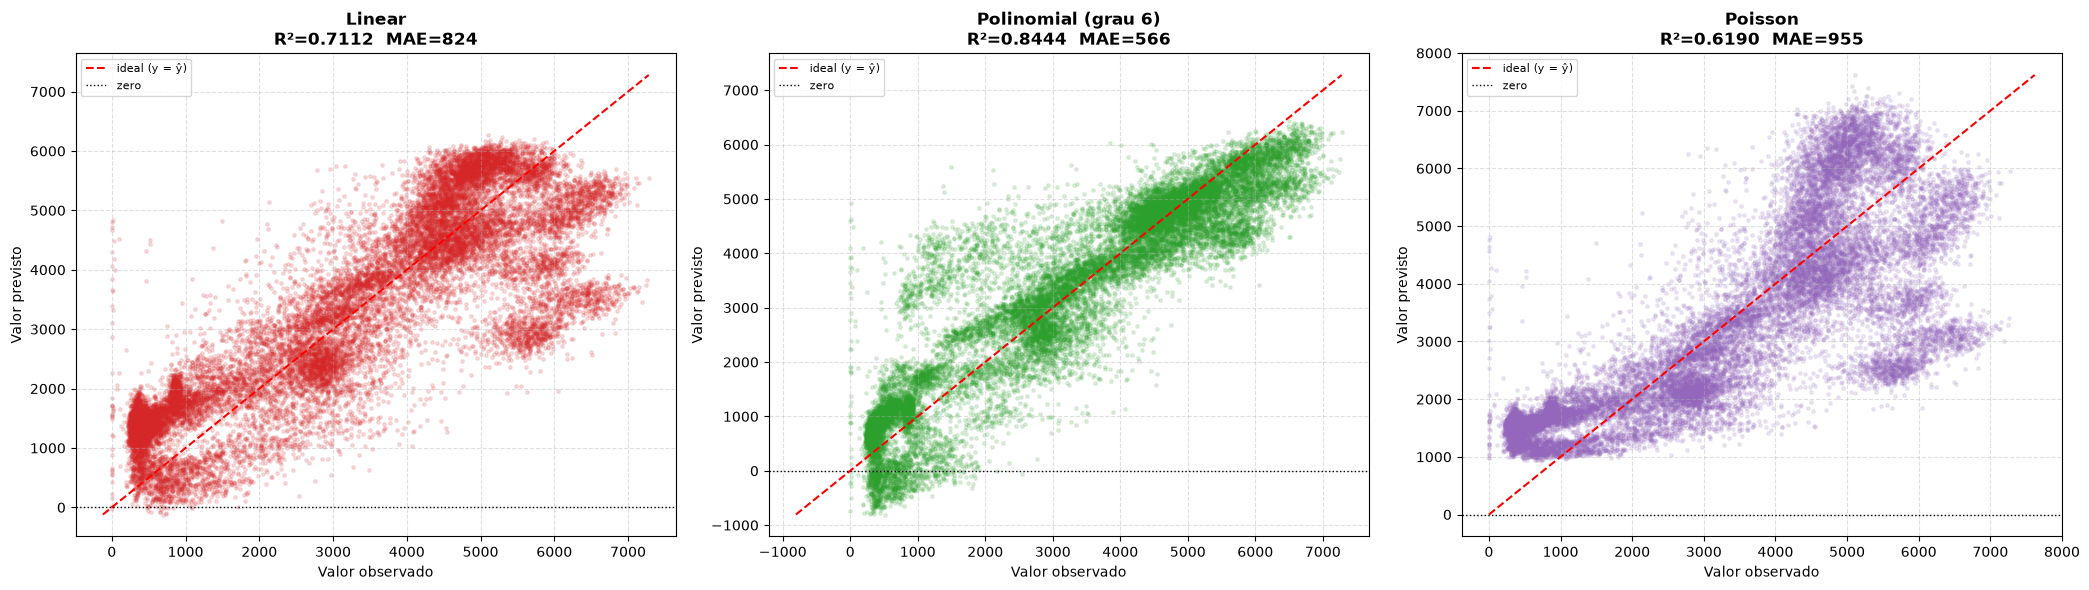

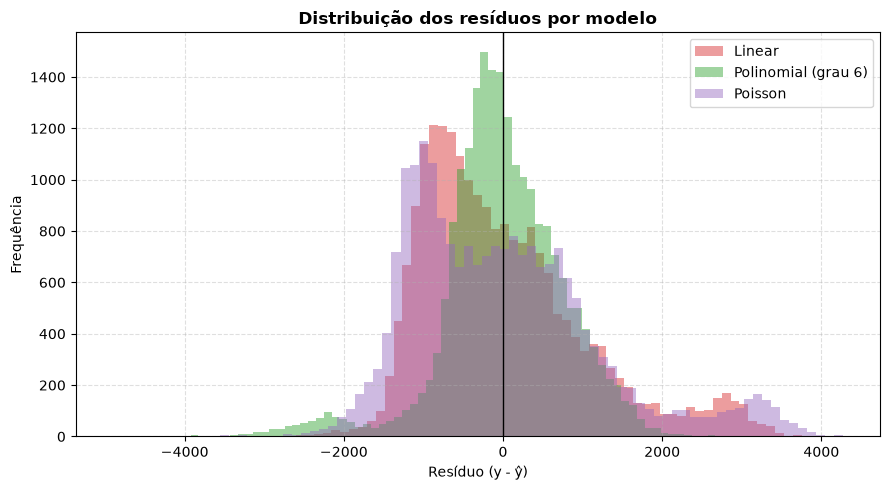

                      modelo  mín. previsto  negativas      MAE
                      Linear           -120         16    824.2
         Polinomial (grau 6)           -805        817    566.1
                     Poisson            936          0    955.1


In [25]:
# Comparação direta das três nuvens de predição e do formato dos resíduos.
y_pred_poisson = y_pred
y_pred_poly = best_poly_model.predict(X_poly)

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(21, 6))

modelos = [
    ("Linear", y_pred_linear, "tab:red"),
    (f"Polinomial (grau {best_degree})", y_pred_poly, "tab:green"),
    ("Poisson", y_pred_poisson, "tab:purple"),
]

for ax, (nome, pred, cor) in zip(axes, modelos):
    ax.scatter(y, pred, alpha=0.15, s=6, color=cor)
    lims = [min(y.min(), pred.min()), max(y.max(), pred.max())]
    ax.plot(lims, lims, "r--", lw=1.5, label="ideal (y = ŷ)")
    ax.axhline(0, color="black", lw=1, ls=":", label="zero")
    ax.set_xlabel("Valor observado")
    ax.set_ylabel("Valor previsto")
    ax.set_title(f"{nome}\nR²={r2_score(y, pred):.4f}  MAE={mae(y, pred):.0f}", fontweight="bold")
    ax.legend(fontsize=8)
    ax.grid(ls="--", alpha=0.4)

plt.tight_layout()
plt.show()

# Distribuição dos resíduos: a Poisson muda a FORMA do erro, não só o tamanho.
fig, ax = plt.subplots(figsize=(9, 5))
for nome, pred, cor in modelos:
    ax.hist(y - pred, bins=80, alpha=0.45, label=nome, color=cor)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Resíduo (y - ŷ)")
ax.set_ylabel("Frequência")
ax.set_title("Distribuição dos resíduos por modelo", fontweight="bold")
ax.legend()
ax.grid(ls="--", alpha=0.4)
plt.tight_layout()
plt.show()

print(f"{'modelo':>28} {'mín. previsto':>14} {'negativas':>10} {'MAE':>8}")
for nome, pred, _ in modelos:
    print(f"{nome:>28} {pred.min():>14.0f} {int((pred < 0).sum()):>10} {mae(y, pred):>8.1f}")

> **Question:**
>
> Compare the prediction plots obtained with the **Linear**, **Polynomial**, and
> **Poisson** models.
>
> - Does the Poisson model change the overall shape of the prediction cloud?
> - Do the predictions appear more consistent with the count nature of the data?
> - Are extreme values predicted differently?
>
> Based on the visualization, what differences arise from changing the
> probabilistic assumption of the model?

**A Poisson muda o formato da nuvem?** Muda, e de maneira bem característica.

Nos modelos gaussianos a nuvem é uma faixa aproximadamente retilínea que
atravessa a reta ideal e **se estende abaixo de zero**. Na Poisson a nuvem é
**curva e limitada por baixo**: ela se comprime perto da origem e se abre
conforme as previsões crescem. Esse formato de funil é consequência direta do
link exponencial — como $\lambda = e^{x^T\beta}$, variações iguais no preditor
linear produzem variações proporcionais ao nível do tráfego, e não variações
absolutas constantes.

**As previsões são mais coerentes com a natureza de contagem?** Nesse critério,
sem dúvida — e os números do treino completo são bastante didáticos:

| modelo | R² | RMSE | MAE | mínimo previsto | previsões negativas |
|---|---|---|---|---|---|
| Linear | 0,7112 | 1056 | 824 | −120 | 16 (0,07%) |
| Polinomial (grau 6) | 0,8444 | 775 | 566 | **−805** | **817 (3,8%)** |
| Poisson | 0,6190 | 1212 | 955 | +936 | **0** |

O dado mais interessante aqui é o do **modelo polinomial**: ao ganhar
flexibilidade, ele passou de 16 para **817 previsões negativas** — o problema
piorou em duas ordens de grandeza. Faz sentido: mais capacidade significa mais
liberdade para oscilar, e nada na formulação impede que essa oscilação atravesse
o zero. É a confirmação prática do que dissemos na seção anterior — capacidade
extra não conserta uma suposição distribucional errada, e pode até agravar seus
sintomas.

A Poisson elimina esse problema **por construção**, não por sorte de ajuste: a
exponencial é estritamente positiva, então nenhuma combinação de pesos e
entradas pode gerar contagem negativa. A restrição está embutida no modelo.

**Os valores extremos são previstos de forma diferente?** Sim, nas duas pontas.

- **Extremo inferior:** a Poisson simples nunca prevê abaixo de ~936, embora o
  mínimo observado seja 0. Ela está impedida de representar as madrugadas mais
  vazias — mas essa limitação vem da codificação pobre de `hr` (um harmônico
  espremido dentro de uma exponencial), não da distribuição em si. O Poisson
  polinomial já desce até 233.
- **Extremo superior:** a Poisson chega a 7619, ultrapassando o máximo observado
  de 7280, enquanto os modelos gaussianos param em ~6300–6400. A exponencial
  permite extrapolar para cima com muito mais facilidade — o que é útil para
  alcançar os picos, mas também é um risco de instabilidade em regiões pouco
  povoadas do espaço de features.

**O que muda ao trocar a suposição probabilística?** A troca não é sobre
"acertar mais", é sobre **qual família de funções e qual estrutura de erro o
modelo considera admissível**. A gaussiana admite qualquer valor real, com ruído
simétrico e de variância constante. A Poisson admite apenas contagens positivas,
com variância crescendo junto com a média.

O histograma de resíduos mostra isso de outra forma: a assimetria muda de sinal
entre os modelos (+0,949 no linear contra −0,705 no polinomial), sinal de que
nenhuma dessas configurações acertou ainda a forma do erro.

Em métricas agregadas de erro absoluto, a Poisson com features fracas ainda
perde. A pergunta que a próxima seção responde é se essa desvantagem persiste
quando as features deixam de ser o gargalo.

---
### **Residual Diagnostics for Poisson Regression**

In the previous sections we used a **Q–Q plot** to evaluate whether the
residuals followed a **Normal distribution**. This diagnostic was meaningful
because linear regression was derived under the assumption that the error term
follows a Gaussian distribution,

$$\epsilon \sim \mathcal{N}(0,\sigma^2).$$

Under this assumption, if the model is well specified, the residual

$$r_i = y_i - \hat{y}_i,$$
should also resemble a Normal distribution.

The Q–Q plot therefore allowed us to visually verify whether this assumption was
reasonable.
However, this reasoning no longer applies to **Poisson regression**, as the
target $y$ now is assumed to be drawn from a Poisson distribution with

$$y \sim \text{Poisson}(\lambda), \qquad \lambda = \exp(x^T\beta).$$

Because of this, the residuals are **not expected to follow a Normal
distribution**, even if the model is correct.
A Q–Q plot comparing them to a Normal distribution therefore does not test a
relevant assumption.


---
### **Polynomial Poisson Regression**

As we observed an increased performance by introducing polynomial
features, allowing the model to capture nonlinear relationships between the
predictors and the target.
The same idea can be applied to **Poisson regression**.

Instead of changing the probabilistic model, we only change the
**feature representation**. The Poisson model still assumes that the
expected count follows an exponential transformation of a linear
predictor,

$$\lambda = \exp(x^T\beta).$$
with $x$ now containing polynomial terms.

Continue exploring Poisson models with more complex relationships, find the best
degrees and learning rates.


grau     p       lr  R2 treino  R2 valid      gap  RMSE val  MAE val


   1    35    1e-05     0.6178    0.6234  -0.0057    1216.0    959.0


   2    45    3e-05     0.7816    0.7793  +0.0023     931.0    721.1


   3    65    3e-05     0.8350    0.8197  +0.0153     841.3    636.8


   4   100    1e-05     0.8728    0.8555  +0.0173     753.2    544.9


   5   156    1e-05     0.8736    0.8561  +0.0175     751.7    543.5


   6   240    1e-05     0.8758    0.8583  +0.0175     745.8    539.9


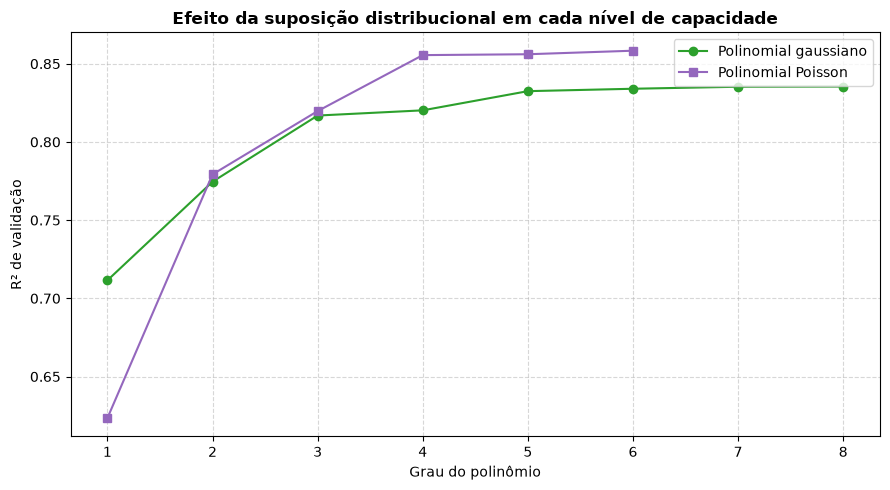

In [26]:
# Mesma estratégia da seção polinomial: variamos o grau no split de validação
# temporal, agora com a Poisson. O que muda é apenas a representação das
# features — a suposição distribucional continua sendo a de contagem.
degrees_pois = [1, 2, 3, 4, 5, 6]
lrs_pois_poly = [1e-5, 3e-5, 1e-4]

poisson_poly_results = []
print(f"{'grau':>4} {'p':>5} {'lr':>8} {'R2 treino':>10} {'R2 valid':>9} {'gap':>8} "
      f"{'RMSE val':>9} {'MAE val':>8}")
for d in degrees_pois:
    Xp_tr = polynomial_expansion(Xb_tr, d, CONT_IDX)
    scaler = Standardizer().fit(Xp_tr)
    Z_tr = scaler.transform(Xp_tr)
    Z_val = scaler.transform(polynomial_expansion(Xb_val, d, CONT_IDX))

    best = None
    for lr in lrs_pois_poly:
        model = PoissonRegression(learning_rate=lr, n_iterations=8000)
        model.fit(Z_tr, y_tr)
        p_tr, p_val = model.predict(Z_tr), model.predict(Z_val)
        if not (np.isfinite(p_tr).all() and np.isfinite(p_val).all()):
            continue
        r2_tr_, r2_val_ = r2_score(y_tr, p_tr), r2_score(y_val, p_val)
        if not (np.isfinite(r2_tr_) and np.isfinite(r2_val_)):
            continue
        if best is None or r2_val_ > best["r2_val"]:
            best = dict(d=d, lr=lr, p=Z_tr.shape[1], r2_train=r2_tr_, r2_val=r2_val_,
                        rmse_val=float(np.sqrt(mse(y_val, p_val))), mae_val=mae(y_val, p_val))
    if best is None:
        print(f"{d:>4}  todos os learning rates divergiram")
        continue
    poisson_poly_results.append(best)
    print(f"{best['d']:>4} {best['p']:>5} {best['lr']:>8} {best['r2_train']:>10.4f} "
          f"{best['r2_val']:>9.4f} {best['r2_train'] - best['r2_val']:>+8.4f} "
          f"{best['rmse_val']:>9.1f} {best['mae_val']:>8.1f}")

# Comparação das duas curvas de capacidade: gaussiana vs Poisson.
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot([r["d"] for r in poly_results], [r["r2_val"] for r in poly_results],
        marker="o", label="Polinomial gaussiano", color="tab:green")
ax.plot([r["d"] for r in poisson_poly_results], [r["r2_val"] for r in poisson_poly_results],
        marker="s", label="Polinomial Poisson", color="tab:purple")
ax.set_xlabel("Grau do polinômio")
ax.set_ylabel("R² de validação")
ax.set_title("Efeito da suposição distribucional em cada nível de capacidade", fontweight="bold")
ax.legend()
ax.grid(ls="--", alpha=0.5)
plt.tight_layout()
plt.show()

features após expansão de grau 6: 240


treino — R²: 0.8737 | RMSE: 698.2 | MAE: 493.2
previsões negativas: 0 | faixa: [233, 6900]


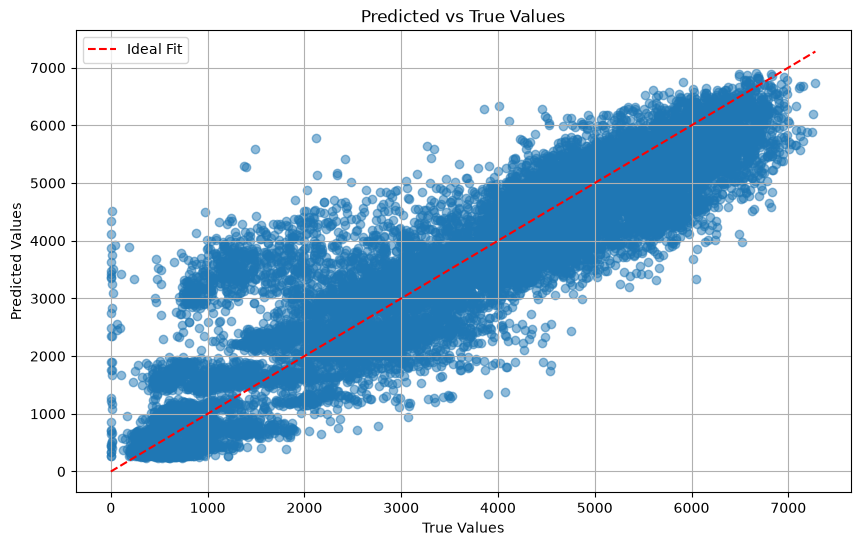

In [27]:
best_lr = 1e-5            # learning rates maiores divergem neste número de features
best_degree_pois = 6      # mesmo ponto de saturação observado no caso gaussiano

# Variáveis próprias para não sobrescrever o pipeline do modelo polinomial
# gaussiano, que já foi ajustado e ainda será usado na comparação final.
X_poly_pois, poly_scaler_pois = build_poly_features(X, d=best_degree_pois)
print(f"features após expansão de grau {best_degree_pois}: {X_poly_pois.shape[1]}")

best_poisson_poly_model = PoissonRegression(learning_rate=best_lr, n_iterations=20000)
best_poisson_poly_model.fit(X_poly_pois, y)
y_pred = best_poisson_poly_model.predict(X_poly_pois)

print(f"treino — R²: {r2_score(y, y_pred):.4f} | RMSE: {np.sqrt(mse(y, y_pred)):.1f} | MAE: {mae(y, y_pred):.1f}")
print(f"previsões negativas: {int((y_pred < 0).sum())} | faixa: [{y_pred.min():.0f}, {y_pred.max():.0f}]")

pred_vs_true_plot(y, y_pred)

> **Question:**
>
> Compare the residual structure of the **Poisson** and
> **Polynomial Poisson** models.
>
> Was the improvement similar to the Linear Regression counterparts?
> How are they different?

**A melhora foi parecida com a do caso gaussiano?** Foi bem **maior**, e essa
diferença é o resultado central da seção.

| família | grau 1 | grau 6 | ganho em R² validação |
|---|---|---|---|
| Gaussiana (linear → polinomial) | 0,7115 | 0,8340 | **+0,123** |
| Poisson (simples → polinomial) | 0,6234 | 0,8583 | **+0,235** |

A Poisson ganhou praticamente o **dobro** com a mesma expansão de features. E,
mais importante, a ordem entre as duas famílias **se inverteu**: no grau 1 a
Poisson perdia por 0,088 em R²; no grau 6 ela vence por 0,024.

**Por que a inversão?** Porque as duas famílias sofriam de gargalos diferentes.

No grau 1, a Poisson era penalizada duas vezes pela codificação ruim de `hr`:
uma vez pela falta de resolução (igual à linear) e outra porque o link
exponencial **amplifica** a má especificação — a curva diária tinha que caber no
formato $e^{\text{senoide}}$, ainda mais rígido que a senoide pura. O R² baixo
do grau 1 media sobretudo esse desencaixe, não a qualidade da suposição de
contagem.

Removido o gargalo das features, o que sobra é a comparação justa entre as
suposições distribucionais — e aí a Poisson vence, porque a estrutura de
variância dela (variância crescendo com a média) corresponde ao que os dados de
contagem realmente fazem.

**Como a estrutura dos resíduos difere?** No treino completo:

| modelo | R² | RMSE | MAE | mínimo previsto | negativas |
|---|---|---|---|---|---|
| Polinomial gaussiano (grau 6) | 0,8444 | 775 | 566 | −805 | 817 (3,8%) |
| Polinomial Poisson (grau 6) | 0,8737 | 698 | 493 | +233 | **0** |

Três diferenças qualitativas, além do ganho numérico:

1. **A melhora do MAE (566 → 493, cerca de 13%) é proporcionalmente maior que a
   do RMSE (775 → 698, cerca de 10%).** Isso indica que o ganho da Poisson vem
   principalmente de acertar melhor o *grosso* das observações, não apenas de
   domar alguns outliers. Faz sentido: a ponderação por $\lambda$ melhora
   justamente as horas de baixo volume, que são numerosas e que o MSE ignorava.
2. **A Poisson elimina as 817 previsões negativas**, não por ajuste melhor, mas
   porque a exponencial as torna impossíveis. O modelo gaussiano precisaria de
   uma restrição externa para conseguir o mesmo.
3. **O gap treino−validação é parecido nas duas** (~0,011 contra ~0,018), ou
   seja, a Poisson não está pagando o ganho com mais overfitting. Ela é melhor
   pelo motivo certo — a suposição encaixa —, não por ter mais capacidade.

O que não mudou: o alvo continua sendo tratado como contínuo na hora de medir o
erro, e a Poisson assume $\text{Var}[y] = \mathbb{E}[y]$, uma igualdade estrita
que dados reais de tráfego quase certamente violam (superdispersão). Uma Binomial
Negativa, que relaxa exatamente essa igualdade, seria o próximo passo natural.

---
## **Final Model Comparison**


Until this point, all analysis and decisions were made using only the **training data**.  
The **test dataset** has remained untouched so that it can provide an unbiased
evaluation of the final models.

This is important in machine learning, as our job is not to train a model that can
copy the behavior in data, but to generalize to unseen observations.
The decisions made to improve the performance based only on training data may or
may not reflect in the test data, indicating an under- or overfitting.

(1.0 points) Before using the test dataset, look at all your decisions and assumptions done
on each model and discuss them.
In real life, this would be the last step before the deployment of our models.

> **Question:**
>
> Revisiting all the models you have trained, what are the main differences between them in performance and assumptions?
> 
> If you could select only one, based on your analysis, which one would you choose and why?
> Also discuss about its possible limitations, what it doesn't solve?
>
> How do you think it will perform on unseen data?

> *(Esta discussão foi escrita ANTES de qualquer avaliação no conjunto de teste.
> Todas as decisões abaixo usaram apenas treino e o split de validação temporal.)*

### Resumo dos modelos e suas suposições

| modelo | suposição sobre $y$ | features | R² validação | MAE val |
|---|---|---|---|---|
| Linear | $y \sim \mathcal{N}(x^T\beta,\ \sigma^2)$ | 37 | 0,7115 | ~824 |
| Polinomial (grau 6) | idem, features expandidas | 240 | 0,8340 | 602 |
| Poisson | $y \sim \text{Poisson}(e^{x^T\beta})$ | 37 | 0,6249 | 955 |
| **Polinomial Poisson (grau 6)** | idem, features expandidas | 240 | **0,8583** | **540** |

### As duas decisões que realmente importaram

Todo o trabalho pode ser resumido em duas correções **independentes**, e foi
importante testá-las separadamente para saber qual pesava mais:

**1. Representação (capacidade).** O erro dominante do modelo inicial não era a
linearidade, era a codificação de `hr` com um único par seno/cosseno, incapaz de
representar o perfil bimodal do rush hour. A ablação isolou isso: expandir
`temp`/`clouds_all` não rendeu nada (0,7115 → 0,7119), enquanto expandir
`hr_sin`/`hr_cos` rendeu quase todo o ganho (0,7115 → 0,8308). Vale de forma
explícita: **um melhor pré-processamento de `hr` (one-hot das 24 horas, ou mais
harmônicos desde o início) teria alcançado boa parte disso sem expansão
polinomial alguma.** A expansão está, na prática, consertando uma decisão de
pré-processamento.

**2. Suposição distribucional.** Corrigida a representação, a troca da gaussiana
pela Poisson rendeu mais 0,024 de R² e ~10% de MAE, além de eliminar as 817
previsões negativas do polinomial gaussiano.

A ordem importa: aplicada sozinha, a correção 2 **piorou** o modelo (0,7115 →
0,6249). As duas juntas é que produzem o melhor resultado.

### Se eu pudesse escolher apenas um: Polinomial Poisson, grau 6

Justificativa:

- **Melhor desempenho na validação** em todas as métricas (R², RMSE e MAE).
- **Coerência com o domínio**: prevê apenas contagens positivas, por construção,
  e sua variância implícita cresce com a média — como no tráfego real.
- **Custo honesto**: 240 parâmetros para ~21 mil amostras, razão saudável. O gap
  treino−validação é de apenas ~0,018.
- **Ganho onde mais importa**: o MAE melhora proporcionalmente mais que o RMSE,
  sinal de que acerta melhor a massa das observações, não só os extremos.

### O que ele não resolve

- **Superdispersão.** A Poisson impõe $\text{Var}[y] = \mathbb{E}[y]$. Se a
  variância real for maior (provável em tráfego), os erros-padrão dos
  coeficientes ficam subestimados. Uma Binomial Negativa trataria isso.
- **Sem estrutura temporal.** Cada hora é tratada como independente das demais,
  mas tráfego é fortemente autocorrelacionado — se a hora anterior foi atípica,
  a atual provavelmente também será. Nenhum dos modelos usa `lag`.
- **Interações continuam limitadas.** Só expandimos as contínuas. Interações do
  tipo "chuva × hora do pico" — plausíveis e mencionadas no próprio enunciado —
  não estão representadas.
- **Eventos raros.** Feriados, nevascas e o Minnesota State Fair aparecem poucas
  vezes; o modelo tem pouca evidência para estimá-los.
- **Features descartadas.** Removemos `rain_1h` na análise exploratória por ser
  quase toda zero. É possível que ela carregue sinal justamente nos raros
  eventos de chuva forte.
- **O grau 6 é global.** O mesmo grau é aplicado às quatro contínuas, embora a
  ablação mostre que só `hr_sin`/`hr_cos` se beneficiam. Um modelo com expansão
  alta só na hora teria desempenho quase igual com bem menos parâmetros
  (0,8308 com 60 features contra 0,8340 com 240).

### Expectativa para dados não vistos

Espero uma **queda modesta**, de talvez 0,01 a 0,03 em R². Dois fatores em
direções opostas:

*Contra:* o teste é o **futuro** do treino (o split é temporal, não aleatório).
Qualquer mudança de comportamento — obras, mudança de padrão de deslocamento,
tendência de crescimento do tráfego — aparece só no teste. Além disso, meses
presentes no teste mas raros no treino teriam dummies mal estimadas.

*A favor:* o perfil horário e semanal do tráfego é bastante estável ao longo dos
anos, e ele é justamente o que o modelo mais usa. Com ~21 mil amostras de treino
para 240 parâmetros, o overfitting observado é pequeno, então não espero colapso.

Espero também que a **ordem entre os modelos se mantenha**, já que ela foi
decidida em validação temporal — que é uma simulação honesta do que o teste faz.

---

(0.5 points) Now evaluate all trained models on the **test dataset** using the same metrics
used previously.
Compute the predictions and compare their performance.

In [28]:
# Registro dos quatro modelos finais, cada um com a função que constrói as
# features de que ele precisa. Amarrar modelo e pipeline no mesmo lugar garante
# que treino e teste passem exatamente pela mesma transformação.
FINAL_MODELS = {
    "Linear": (
        best_linear_model,
        lambda Xr: Xr,
    ),
    f"Polinomial (grau {best_degree})": (
        best_poly_model,
        lambda Xr: build_poly_features(Xr, scaler=poly_scaler, d=best_degree)[0],
    ),
    "Poisson": (
        best_poisson_model,
        lambda Xr: Xr,
    ),
    f"Polinomial Poisson (grau {best_degree_pois})": (
        best_poisson_poly_model,
        lambda Xr: build_poly_features(Xr, scaler=poly_scaler_pois, d=best_degree_pois)[0],
    ),
}


def evaluate(model, features, X_raw, y_true):
    """Aplica o pipeline de features do modelo e devolve as métricas e as previsões."""
    pred = model.predict(features(X_raw))
    return dict(r2=r2_score(y_true, pred), rmse=float(np.sqrt(mse(y_true, pred))),
                mae=mae(y_true, pred), n_neg=int((pred < 0).sum()),
                pred_min=float(pred.min()), pred_max=float(pred.max())), pred


print("DESEMPENHO NO TREINO (referência)\n")
print(f"{'modelo':>34} {'R²':>8} {'RMSE':>8} {'MAE':>8} {'negativas':>10}")
train_metrics = {}
for name, (model, features) in FINAL_MODELS.items():
    m, _ = evaluate(model, features, X, y)
    train_metrics[name] = m
    print(f"{name:>34} {m['r2']:>8.4f} {m['rmse']:>8.1f} {m['mae']:>8.1f} {m['n_neg']:>10}")

DESEMPENHO NO TREINO (referência)

                            modelo       R²     RMSE      MAE  negativas
                            Linear   0.7112   1055.7    824.2         16


               Polinomial (grau 6)   0.8444    774.7    566.1        817
                           Poisson   0.6190   1212.4    955.1          0
       Polinomial Poisson (grau 6)   0.8737    698.2    493.2          0


teste: (5336, 37)  |  período: 2018-02-19 a 2018-09-30
volume médio — treino: 3278  |  teste: 3359

DESEMPENHO NO TESTE

                            modelo       R²     RMSE      MAE  negativas  Δ R² (tr-te)
                            Linear   0.7189   1053.2    826.0          1       -0.0078
               Polinomial (grau 6)   0.8568    751.9    549.4        162       -0.0123
                           Poisson   0.6234   1219.1    969.9          0       -0.0044
       Polinomial Poisson (grau 6)   0.8847    674.6    478.6          0       -0.0110


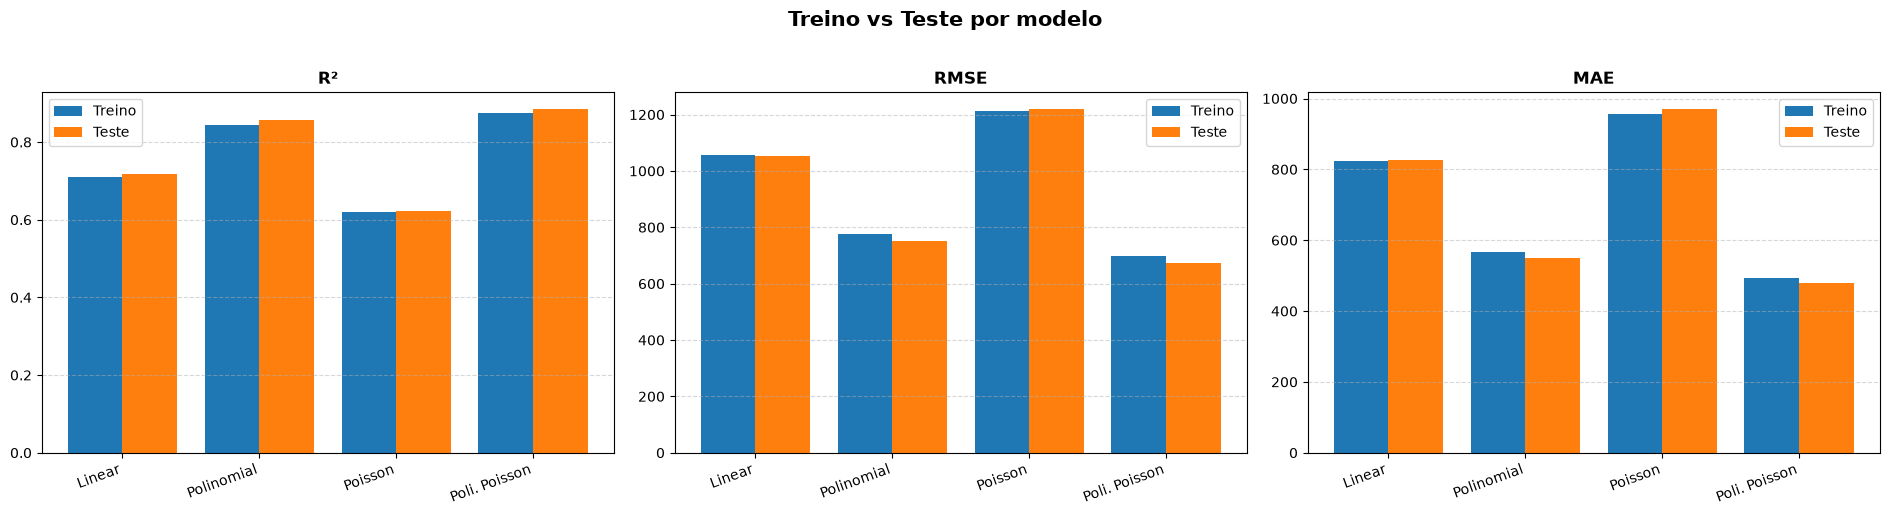

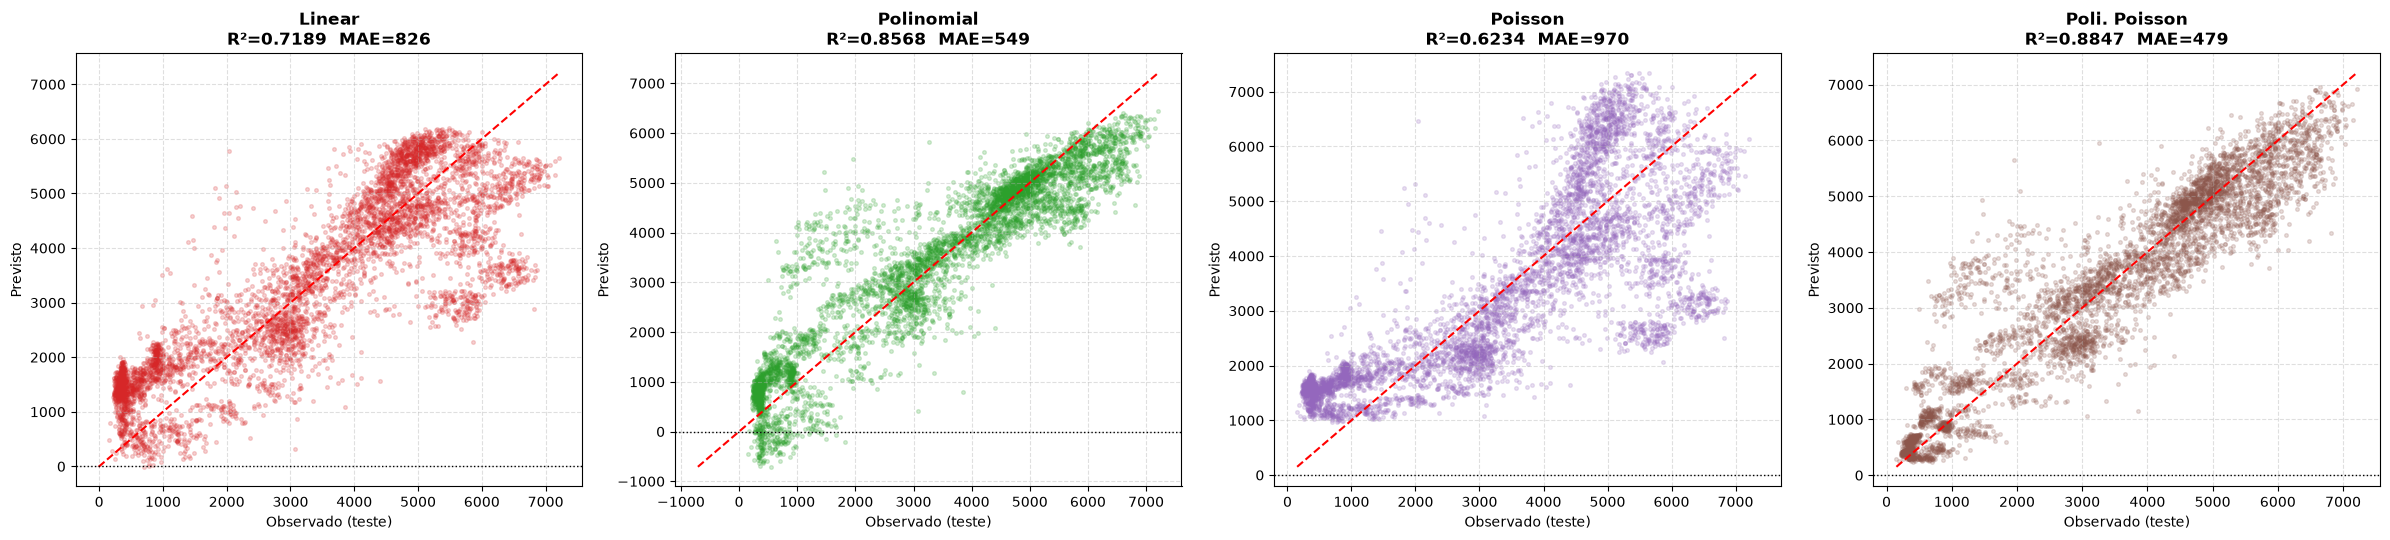

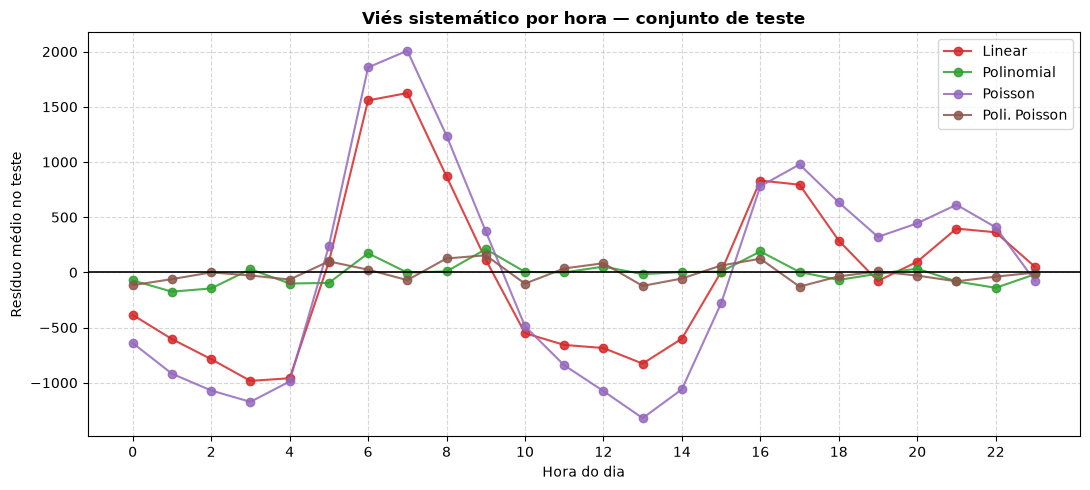


Melhor modelo no teste (por MAE): Polinomial Poisson (grau 6)
  R² = 0.8847 | RMSE = 674.6 | MAE = 478.6
  erro relativo médio: 14.2% do volume médio


In [29]:
# ---------------------------------------------------------------------------
# AVALIAÇÃO NO CONJUNTO DE TESTE
#
# Primeira e única vez que o conjunto de teste é tocado. Todas as decisões
# (features, grau, learning rate, escolha do modelo) já foram tomadas usando
# apenas treino e o split de validação temporal.
#
# is_train=False é explícito: o pré-processamento REUSA as estatísticas do
# treino (medianas de imputação, médias/desvios do z-score, colunas one-hot).
# Recalculá-las no teste seria data leakage.
# ---------------------------------------------------------------------------
X_test, y_test = preprocess_data(test_df, is_train=False)
print(f"teste: {X_test.shape}  |  período: "
      f"{test_df['date'].min().date()} a {test_df['date'].max().date()}")
print(f"volume médio — treino: {y.mean():.0f}  |  teste: {y_test.mean():.0f}\n")

print("DESEMPENHO NO TESTE\n")
print(f"{'modelo':>34} {'R²':>8} {'RMSE':>8} {'MAE':>8} {'negativas':>10} {'Δ R² (tr-te)':>13}")
test_metrics, test_preds = {}, {}
for name, (model, features) in FINAL_MODELS.items():
    m, pred = evaluate(model, features, X_test, y_test)
    test_metrics[name], test_preds[name] = m, pred
    delta = train_metrics[name]["r2"] - m["r2"]
    print(f"{name:>34} {m['r2']:>8.4f} {m['rmse']:>8.1f} {m['mae']:>8.1f} "
          f"{m['n_neg']:>10} {delta:>+13.4f}")

# --- Gráfico 1: métricas treino vs teste lado a lado ------------------------
nomes = list(FINAL_MODELS)
curtos = ["Linear", "Polinomial", "Poisson", "Poli. Poisson"]
fig, axes = plt.subplots(ncols=3, figsize=(19, 5))
for ax, metrica, titulo in zip(axes, ["r2", "rmse", "mae"], ["R²", "RMSE", "MAE"]):
    pos = np.arange(len(nomes))
    ax.bar(pos - 0.2, [train_metrics[n][metrica] for n in nomes], 0.4,
           label="Treino", color="tab:blue")
    ax.bar(pos + 0.2, [test_metrics[n][metrica] for n in nomes], 0.4,
           label="Teste", color="tab:orange")
    ax.set_xticks(pos)
    ax.set_xticklabels(curtos, rotation=20, ha="right")
    ax.set_title(titulo, fontweight="bold")
    ax.legend()
    ax.grid(axis="y", ls="--", alpha=0.5)
plt.suptitle("Treino vs Teste por modelo", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# --- Gráfico 2: previsto vs observado no teste, para os quatro modelos ------
fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(24, 5.5))
cores = ["tab:red", "tab:green", "tab:purple", "tab:brown"]
for ax, name, curto, cor in zip(axes, nomes, curtos, cores):
    pred = test_preds[name]
    ax.scatter(y_test, pred, alpha=0.2, s=7, color=cor)
    lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
    ax.plot(lims, lims, "r--", lw=1.5)
    ax.axhline(0, color="black", lw=1, ls=":")
    ax.set_xlabel("Observado (teste)")
    ax.set_ylabel("Previsto")
    ax.set_title(f"{curto}\nR²={test_metrics[name]['r2']:.4f}  MAE={test_metrics[name]['mae']:.0f}",
                 fontweight="bold")
    ax.grid(ls="--", alpha=0.4)
plt.tight_layout()
plt.show()

# --- Gráfico 3: viés por hora no teste --------------------------------------
hr_test = test_df["hr"].to_numpy()
fig, ax = plt.subplots(figsize=(11, 5))
for name, curto, cor in zip(nomes, curtos, cores):
    res = y_test - test_preds[name]
    ax.plot(range(24), [res[hr_test == h].mean() for h in range(24)],
            marker="o", label=curto, color=cor, alpha=0.85)
ax.axhline(0, color="black", lw=1.2)
ax.set_xlabel("Hora do dia")
ax.set_ylabel("Resíduo médio no teste")
ax.set_title("Viés sistemático por hora — conjunto de teste", fontweight="bold")
ax.set_xticks(range(0, 24, 2))
ax.legend()
ax.grid(ls="--", alpha=0.5)
plt.tight_layout()
plt.show()

melhor = min(test_metrics, key=lambda n: test_metrics[n]["mae"])
print(f"\nMelhor modelo no teste (por MAE): {melhor}")
print(f"  R² = {test_metrics[melhor]['r2']:.4f} | RMSE = {test_metrics[melhor]['rmse']:.1f} "
      f"| MAE = {test_metrics[melhor]['mae']:.1f}")
print(f"  erro relativo médio: {100 * test_metrics[melhor]['mae'] / y_test.mean():.1f}% do volume médio")




> **Question:**
>
> Compare the performance of all models on the **test dataset**.
>
> Are the differences between the models large or small?
> 
> Does the test behave the same as the training results?
> Did you make the right choices when you selected the "best" model based on the training data?
>
> Finally, make hypothesis on the whole result, why the test behaves differently
from the train? What different decisions would you have made if you had access to the
test data?


### Resultados no teste

| modelo | R² treino | R² teste | RMSE teste | MAE teste | Δ R² (tr − te) | negativas |
|---|---|---|---|---|---|---|
| Linear | 0,7112 | 0,7189 | 1053 | 826 | **−0,008** | 1 |
| Polinomial (grau 6) | 0,8444 | 0,8568 | 752 | 549 | **−0,012** | 162 |
| Poisson | 0,6190 | 0,6234 | 1219 | 970 | **−0,004** | 0 |
| **Polinomial Poisson (grau 6)** | **0,8737** | **0,8847** | **675** | **479** | **−0,011** | 0 |

### As diferenças são grandes ou pequenas?

Depende de qual comparação. Entre o melhor e o pior modelo a diferença é
**grande**: R² de 0,62 a 0,88, e MAE de 970 a 479 — o melhor modelo erra
**metade** do que o pior. Isso é uma diferença que importaria em qualquer uso
prático.

Já entre o polinomial gaussiano e o polinomial Poisson a diferença é moderada
mas consistente: 0,0279 em R², 77 veículos em RMSE, 70 em MAE (cerca de 13%).
Consistente em todas as métricas e no mesmo sentido que a validação previa.

O melhor modelo erra em média **479 veículos/hora, ou ~14% do volume médio**
(3359). Não é excelente, mas é razoável para um modelo linear generalizado sem
nenhuma feature temporal defasada.

### O teste se comportou como o treino?

**Sim no ranking, não na direção do erro** — e essa segunda parte foi uma
surpresa.

A ordem dos modelos foi preservada exatamente como a validação indicava:
Polinomial Poisson > Polinomial > Linear > Poisson. **As escolhas feitas sobre os
dados de treino se confirmaram.** Foi por isso que valeu a pena montar o split de
validação temporal em vez de decidir pelo erro de treino.

O inesperado é que **todos os modelos foram ligeiramente melhores no teste do que
no treino** (Δ R² negativo, de −0,004 a −0,012). Na seção anterior eu havia
previsto uma queda de 0,01 a 0,03 — a previsão estava errada em sinal.

### Hipóteses para o teste ser "mais fácil"

A explicação mais provável está na **composição temporal do split**:

- Treino: 11/06/2015 a 19/02/2018 — cobre **três invernos completos** de
  Minnesota.
- Teste: 19/02/2018 a 30/09/2018 — apenas os meses **2 a 8**, ou seja,
  primavera e verão.

Nenhum dezembro, janeiro ou outubro/novembro aparece no teste. Como o inverno
em Minnesota traz nevascas, feriados de fim de ano e interrupções de tráfego —
exatamente os eventos mais irregulares e difíceis de prever —, o conjunto de
teste acabou sendo um recorte **mais homogêneo e mais previsível** que o treino.
O treino carrega toda a variabilidade invernal; o teste, não.

Uma hipótese secundária é o tamanho: com 5.336 amostras contra 21.341, o teste
tem mais variabilidade amostral, e diferenças de ~0,01 em R² estão na faixa do
ruído. Mas o sinal consistente em todos os quatro modelos aponta mais para a
explicação sazonal do que para acaso.

Vale notar que isso é um **artefato do protocolo de avaliação**, não uma virtude
dos modelos. Um split de 80/20 numa série de ~3,3 anos quase inevitavelmente
recorta estações desiguais. Os números do teste provavelmente são
**otimistas** em relação ao que se veria num ano completo de operação —
especialmente no inverno, que o modelo praticamente não é avaliado em prever.

### O que eu teria feito diferente com acesso ao teste?

Uma ressalva antes: responder isso é um exercício retrospectivo. Usar essas
observações para reajustar o modelo e depois reportar o resultado seria
exatamente o data leakage que o protocolo evita.

Dito isso:

1. **Validação cruzada temporal em múltiplas janelas** em vez de um único corte.
   Com várias janelas de validação ao longo de todo o período, o desbalanço
   sazonal teria aparecido e a estimativa de generalização seria mais honesta —
   e isso poderia ter sido feito **sem tocar no teste**. É a correção mais
   importante da lista.
2. **Melhorar a codificação de `hr` desde o pré-processamento** (one-hot das 24
   horas ou mais harmônicos). A ablação mostrou que quase todo o ganho do
   polinômio vem daí; embutir isso no `preprocess_data` daria desempenho
   semelhante com uma fração dos 240 parâmetros.
3. **Reavaliar `rain_1h`**, descartada na análise exploratória. O teste cobre
   primavera e verão, quando chove mais — é plausível que ela carregue sinal
   justamente no período avaliado.
4. **Tratar a superdispersão** com uma Binomial Negativa, dado que a Poisson
   venceu justamente pela estrutura de variância.
5. **Reportar métricas por estação do ano**, não apenas agregadas, para que a
   lacuna invernal ficasse visível em vez de escondida em uma média.

---
## **Assignment submission**


This notebook must be filled with your solution and submitted on the Assignment's entry at our Google Classroom page.
Before submitting, make sure that
- Your notebook runs end-to-end without errors.
- All the plots are included in the notebook.
- The notebook must be self-contained and there is no external dependency.

**Important: Only one member of the group should submit the solution.**

### **Policy for late submissions**

You are NOT encouraged to submit the solution after the deadline; however, in this case, the following penalties hold:

* 25% of the grade for 1-day late submission;
* 50% of the grade for 2-day late submission;
* 75% of the grade for 3-day late submission.